# STD model with $c_{TD} = 1$
Shows that slightly different parameters are obtained when correlation between sister TA cell division and D cell delamination is allowed. Comparable quality of fits are obtained
This result is discussed in Supplementary Note, but no figures are shown in the paper.


## Running fitting: 
These sims will go in the same searchspace as before but they are filtered in the spreadsheet. Alternatively, you can explicitly save them to a different folder.

### Finding best fits
To find best fits with simulated annealing run: [FitSTD.py](../../modelling/FitSTD.py):
```bash
#Comment out the model use
mode=1 #Use 2D
#mode=0 #Use 0D


#Males 
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 1.0  1.0 0.5 0 ::: {-200..-181} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode M 1000 1.0  1.0 0.5 2 ::: {-300..-281} &

#Females
0 0.5 0 ::: {-180..-161} &
parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 1.0  1.parallel --max-procs 5 python3.12 FitSTD.py {1} 1 $mode F 1000 1.0  1.0 0.5 2 ::: {-300..-281} &

```

At the end to combine files run:
```bash
#Analyse simulations
python3.12 FitSTD.py -1000 1 0 M -2000 &
python3.12 FitSTD.py -1000 1 0 F -2000 &
```


### Estimating parameter uncertainty with grid search+bootstrapping
To estimate parameter uncertainty run: [FitSTD.py](../../modelling/FitSTD.py):


```bash
#Run bootstrapping
parallel --max-procs 50 python3.12 FitSTD.py {1} 1 $mode M 1000 1.0 1.0 0.5 0 1.0 ::: {0..12000} &
parallel --max-procs 50 python3.12 FitSTD.py {1} 1 $mode F 1000 1.0 1.0 0.5 0 1.0 ::: {0..12000} &


#Analyse simulations
python3.12 FitSTD.py -1000 1 0 M 1000 &
python3.12 FitSTD.py -1000 1 0 F 1000 &
```


In [ ]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
import sys
import pickle

sys.path.append("../../analysis/")
sys.path.append("../../sim/")
sys.path.append("../../fit/")
sys.path.append("../../plot/")


from tissue import *
import tissplot as tplt
import matplotlib.path as mplPath
import analysis
import datasets as ds 
import tiss_optimize as topt
import sim_model
import os
import custom_metrics as cmet



#Metrics
ksdists  = {'dist': ['S2like.basalCS', 'S2like.supraCS'], 'dist_metric': 'ksd', 'name': 'ksd_b_sb'}
k1dists  = {'dist': ['S2like.basalCS'], 'dist_metric': 'ksd', 'name': 'ksd_bas'}

ll_dist_STD = {'dist': ['Slike.fullbasalCS', 'Slike.fullsupraCS',
                    'Tlike.fullbasalCS', 'Tlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS', 
                    'S2like.xfrac'], 
                    'dist_metric': 'lLL', 'name': 'll_STD'}

ll_dist_SPD = {'dist': ['S4like.fullbasalCS', 'S4like.fullsupraCS',
                    'CPlike.fullbasalCS', 'CPlike.fullsupraCS',
                    'Dlike.fullbasalCS', 'Dlike.fullsupraCS'], 
                    'dist_metric': 'lLL', 'name': 'll_SPD'}
T0 = 50
mets = [ll_dist_SPD, ll_dist_STD, ksdists, k1dists] 
compute_kwargs = {'Dlike': {'containsBasal': False}}
toCalculate = ['basalCS', 'S4like.basalCS', 'S4like.supraCS', 'CPlike.basalCS', 'CPlike.supraCS', 'Dlike.basalCS', 'Dlike.supraCS',
               'Tlike.basalCS', 'Tlike.supraCS', 'Slike.basalCS', 'Slike.supraCS', 'S2like.basalCS', 'S2like.supraCS',
               'T3like.basalCS', 'T3like.supraCS', 'S2like.xfrac', 'Slike.xfrac', 'Tlike.xfrac', 'Dlike.xfrac',
               'S4like.lcd', 'T3like.lcd', 'CPlike.lcd', 'Dlike.lcd', 'Slike.lcd', 'Tlike.lcd', 'S2like.lcd',
               'S4like.pers', 'T3like.pers', 'CPlike.pers', 'Dlike.pers', 'Slike.pers', 'Tlike.pers', 'S2like.pers',]


from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 10
rcParams['xtick.labelsize'] = 7.5
rcParams['ytick.labelsize'] = 7.5
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 7.5  # General font size
rcParams['text.usetex'] = False
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5



1 0 castre
castre 2881.7153009502385 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_0.5_CVd_T_-1.0_corrDD_1.0_corrSS_0.5_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_0.5_r_0.075_refractT_-1.0_rhoS_0.275_tau_100.0_seed_0.pkl
tscale: -5.3
τ range: 1.8 to 140.0
shed: -0.7 refract: 0.0 cv: 1.0
Already cropped
Already cropped


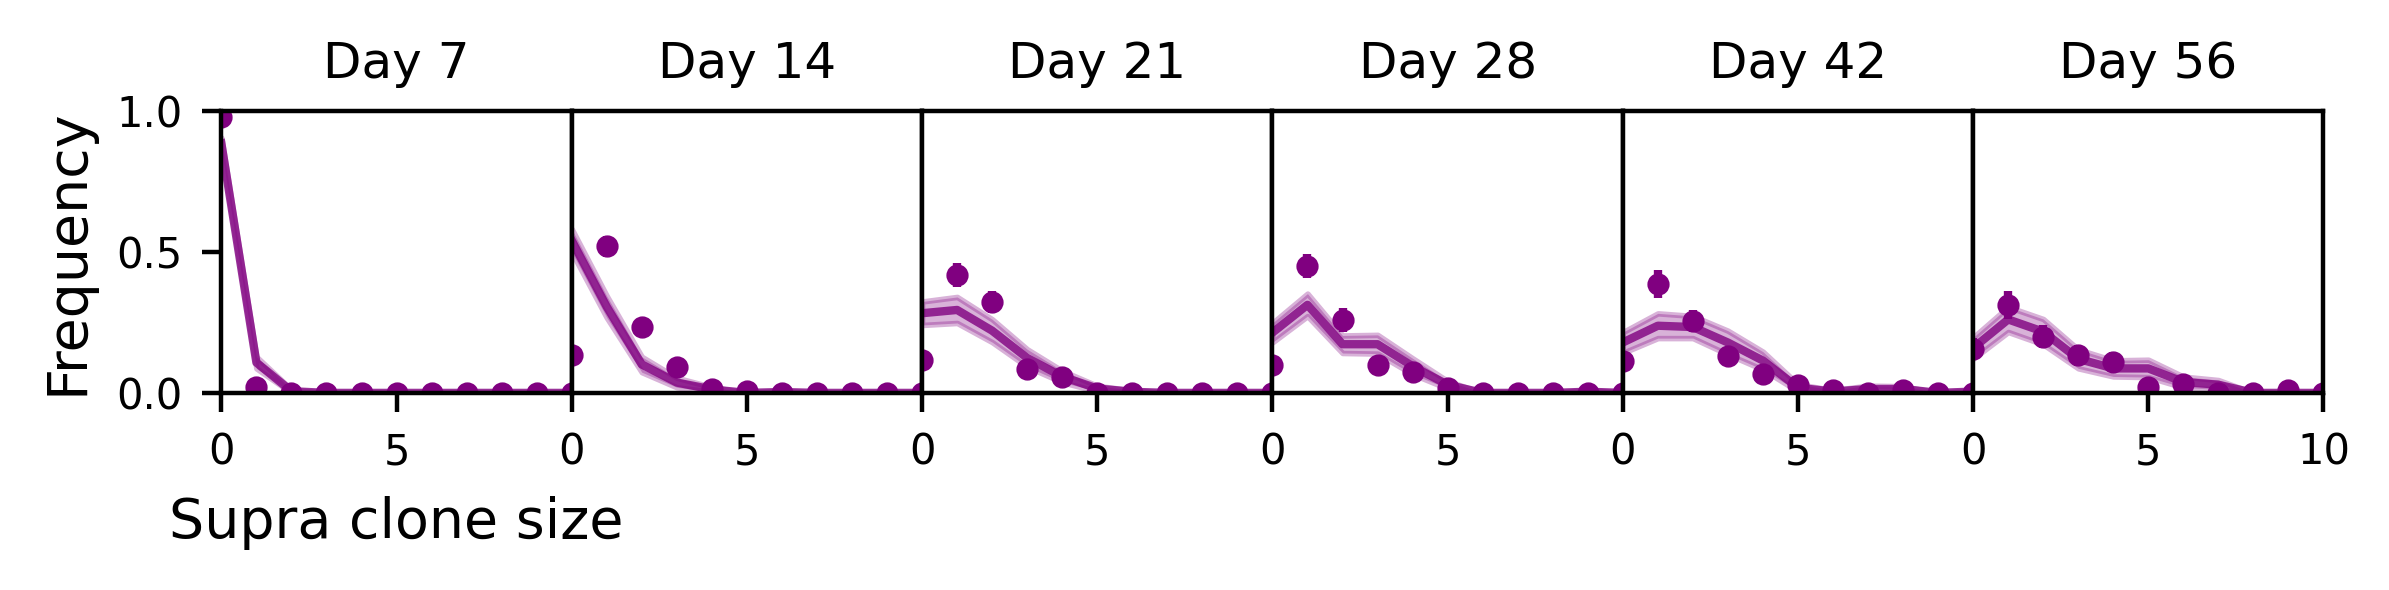

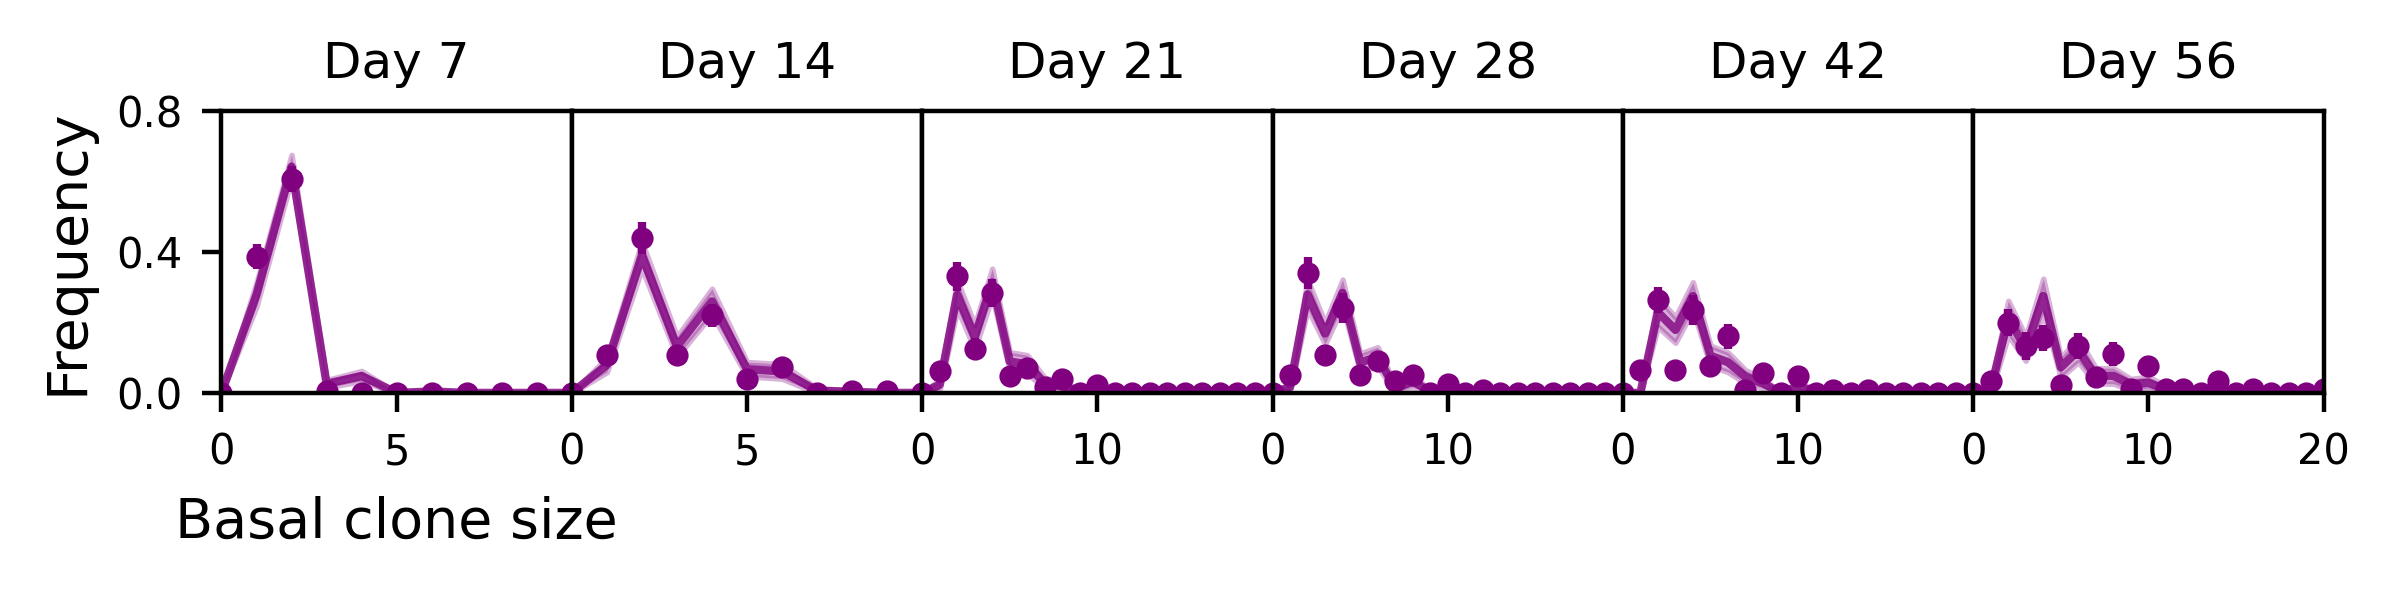

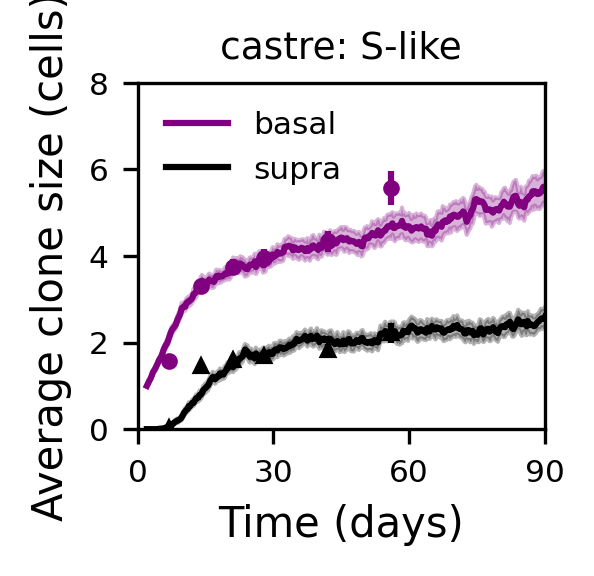

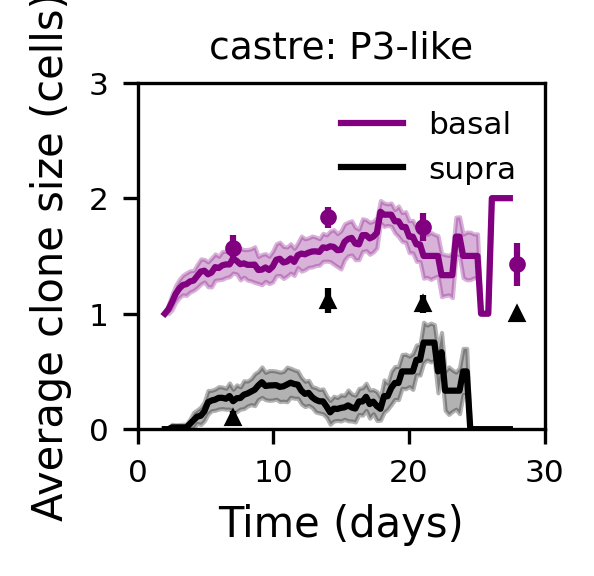

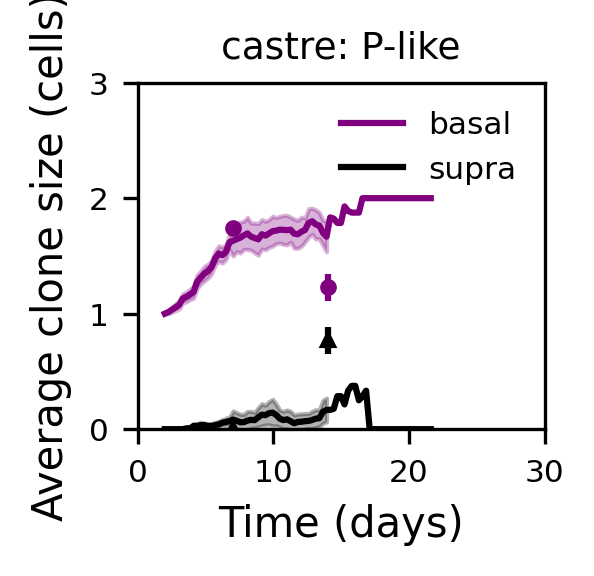

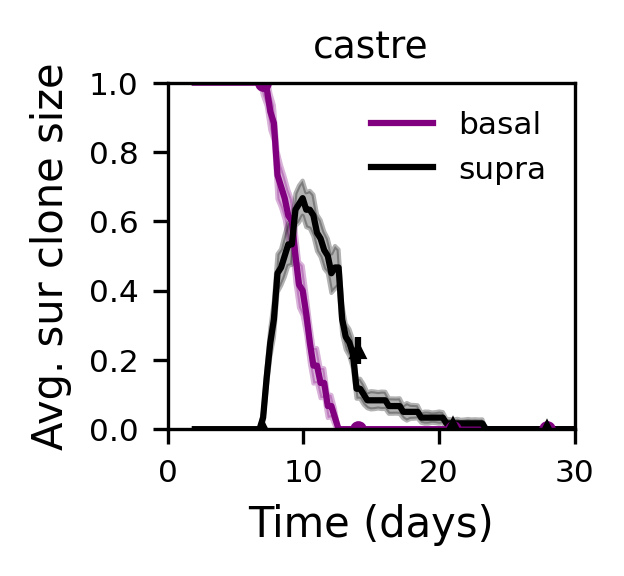

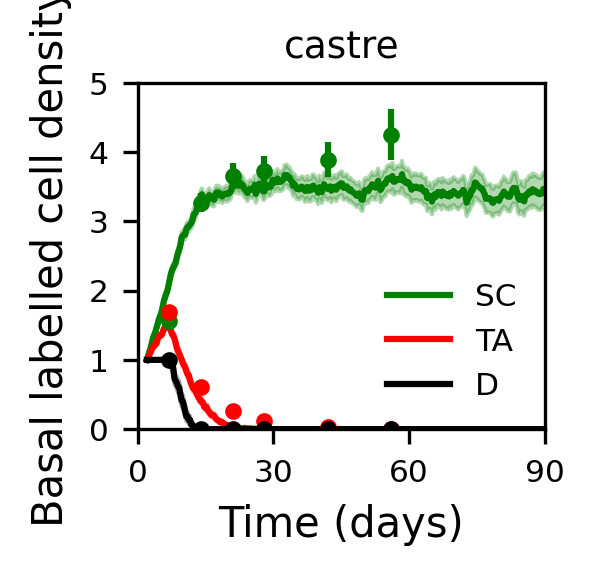

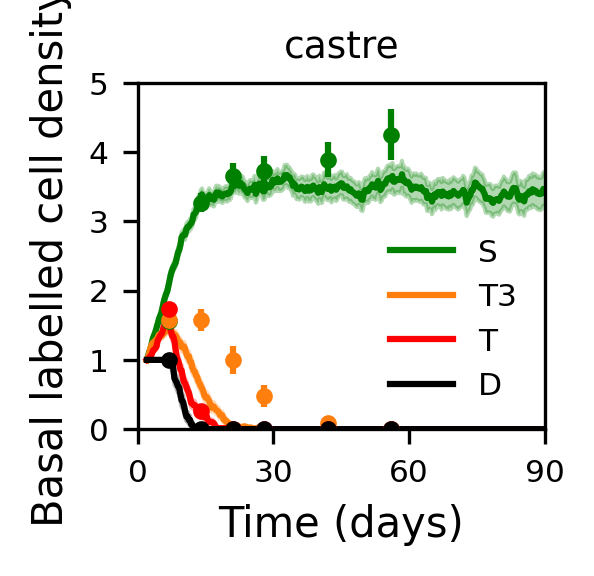

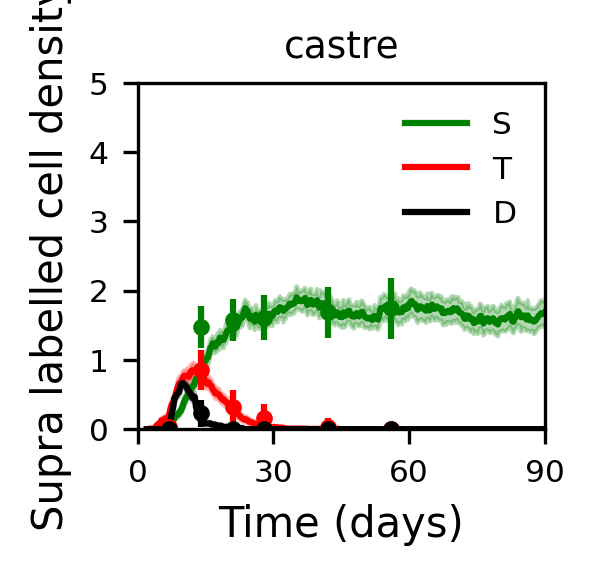

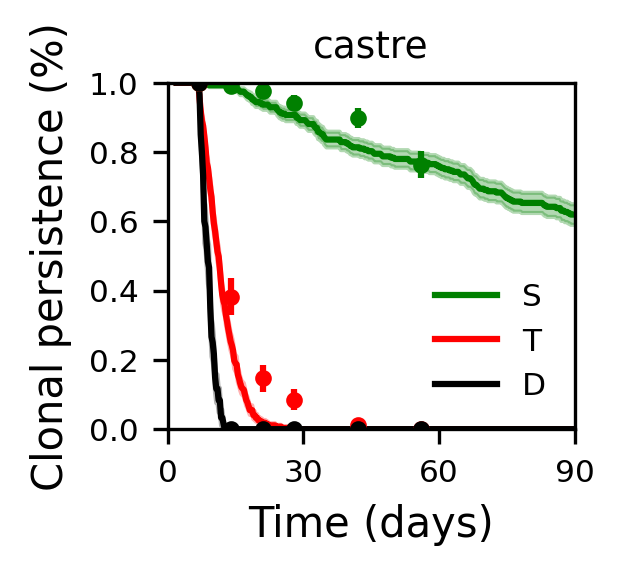

Already cropped


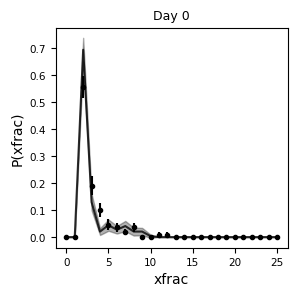




castre 1.3194257568283483 ksd_b_sb
hrun_ST2D_0D_t_-30_n_1000_CVd_D_0.2_CVd_S_0.5_CVd_T_-1.0_corrDD_0.4_corrSS_0.3_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_0.5_r_0.075_refractT_-1.0_rhoS_0.275_tau_100.0_seed_0.pkl
tscale: -5.95
τ range: 1.8 to 140.0
shed: -0.7 refract: 0.0 cv: 1.0
Already cropped
Already cropped


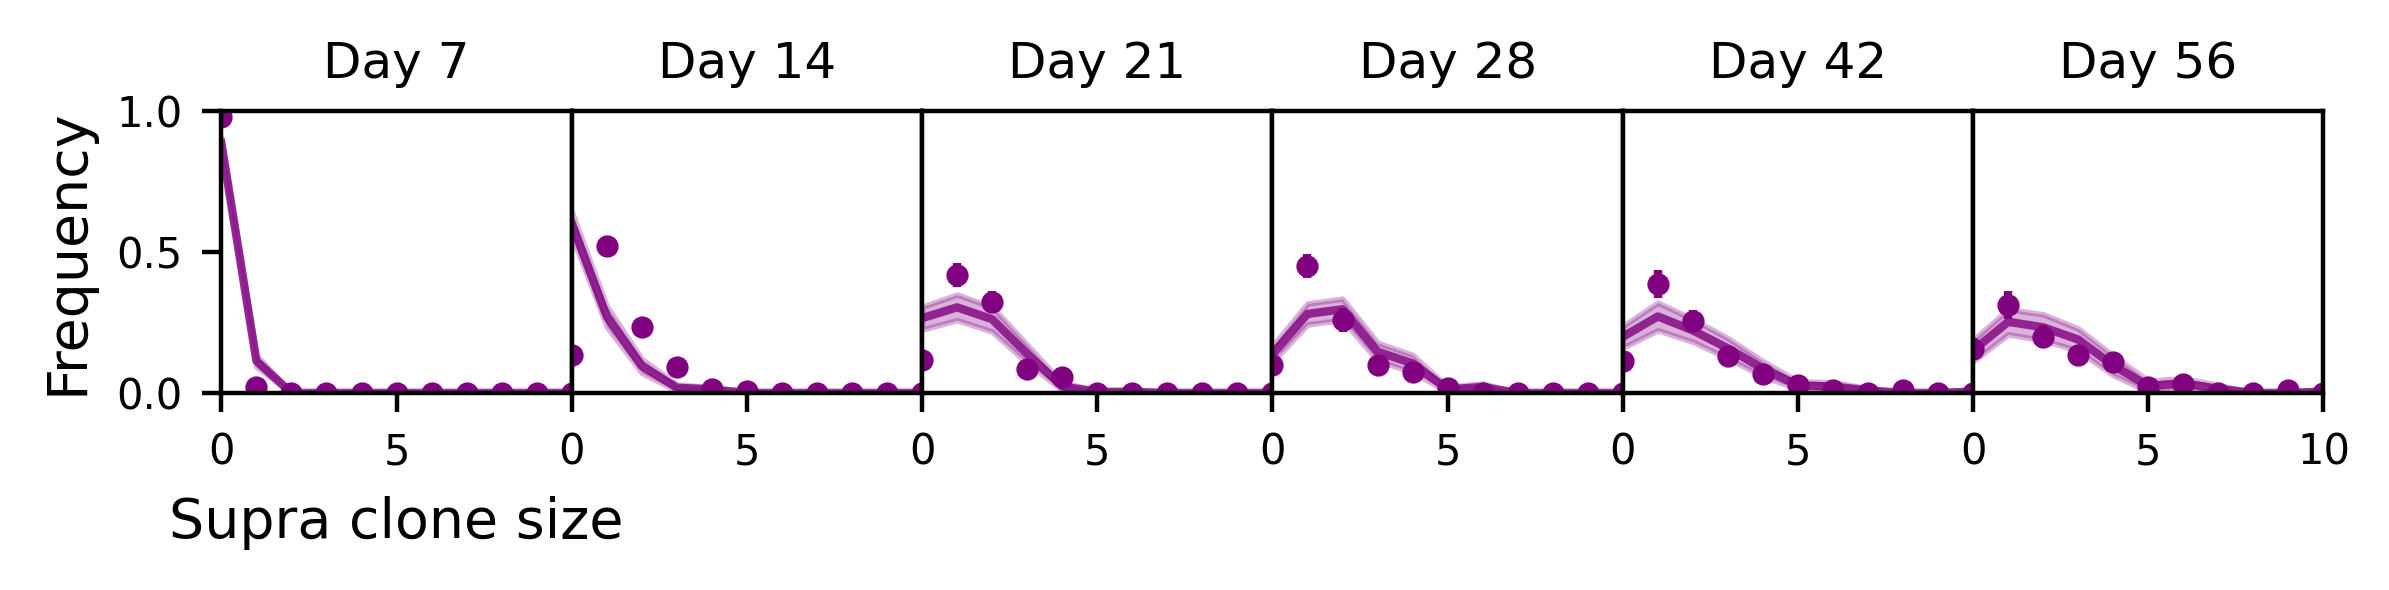

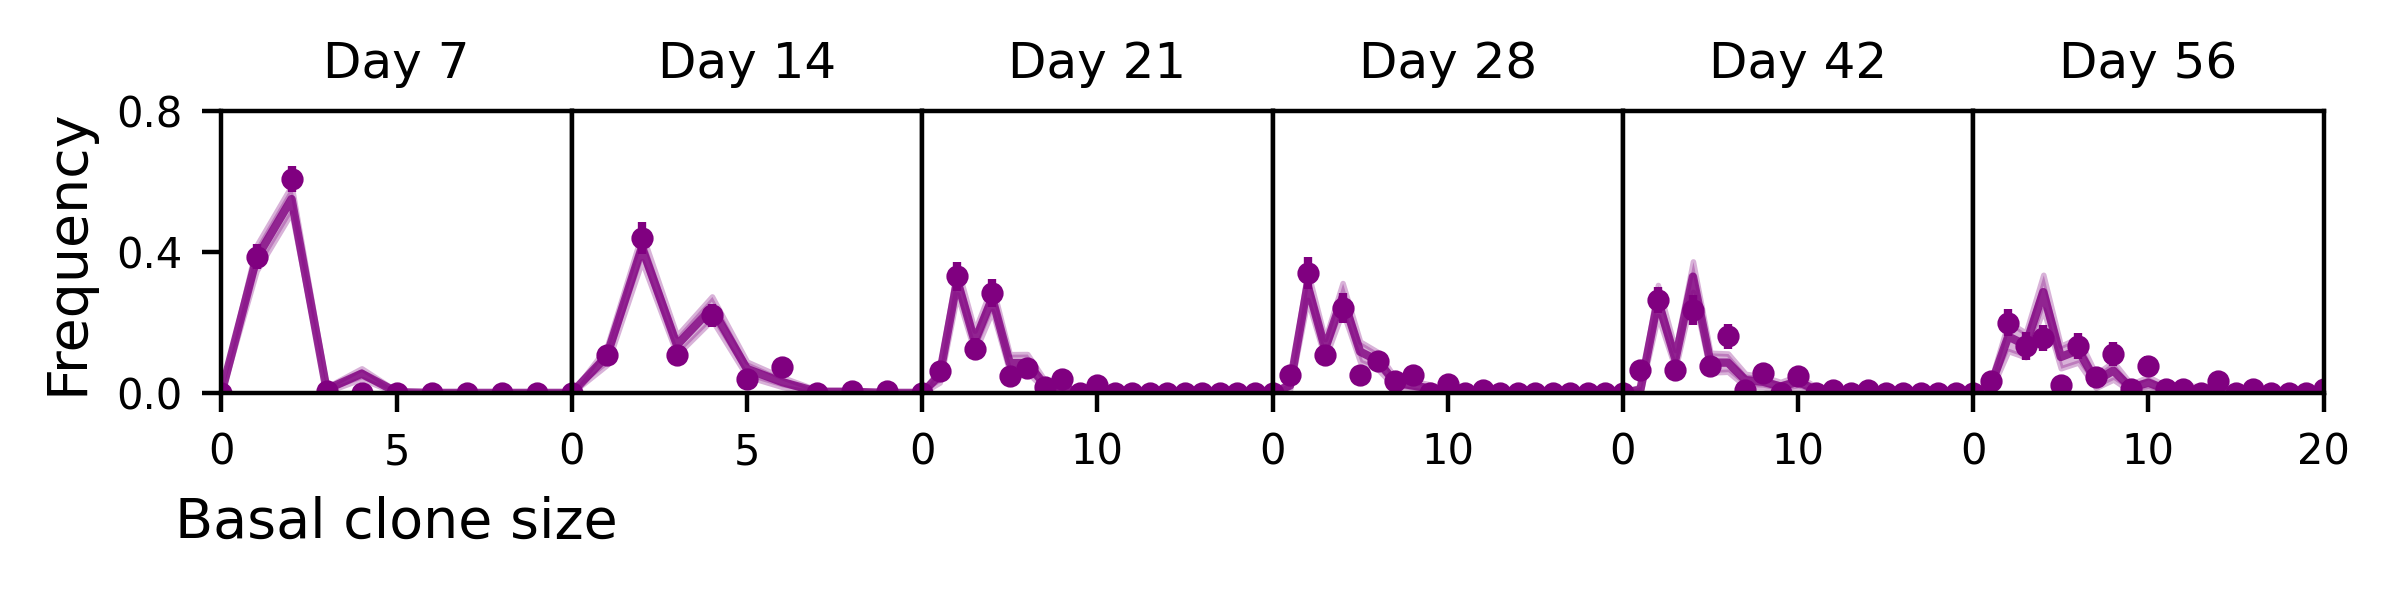

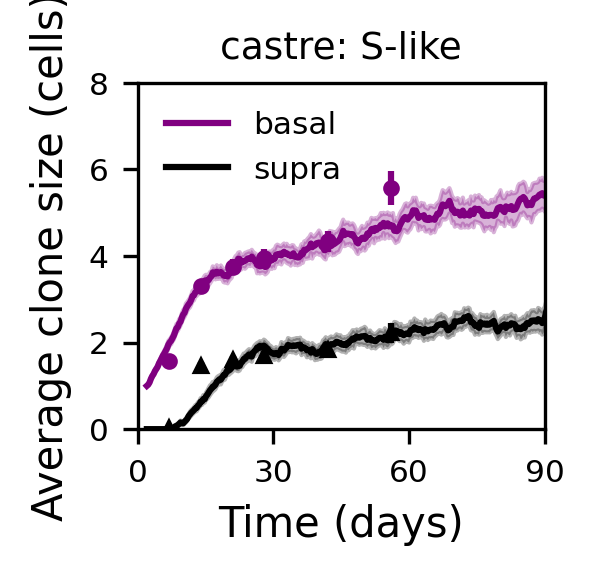

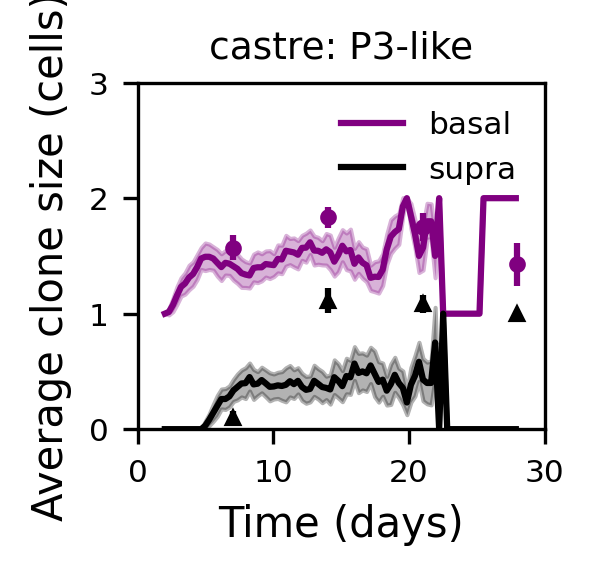

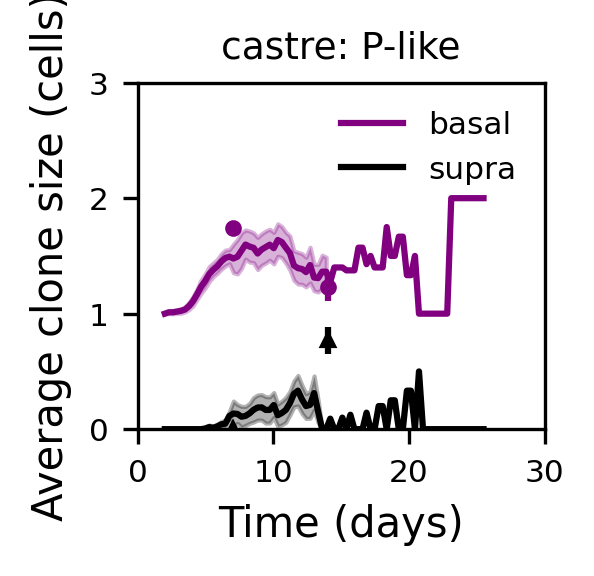

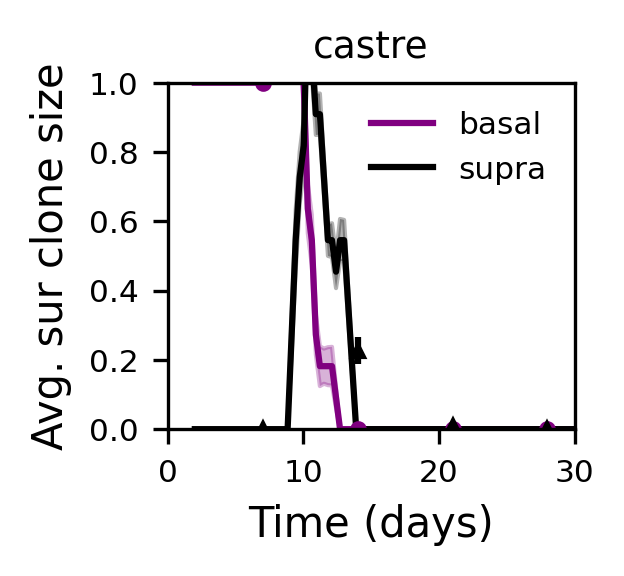

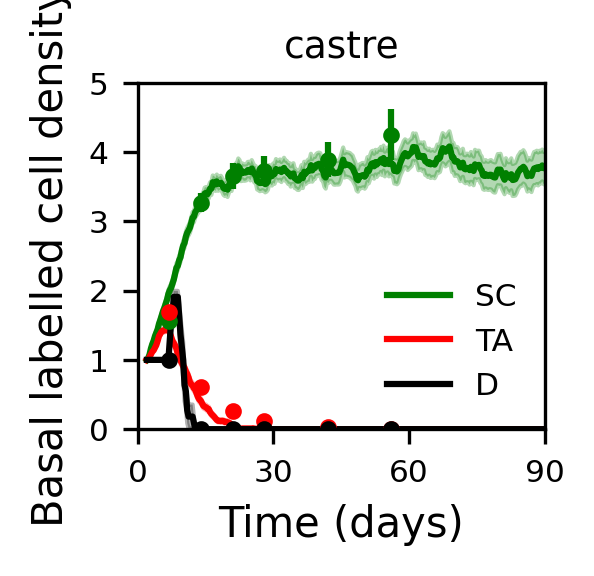

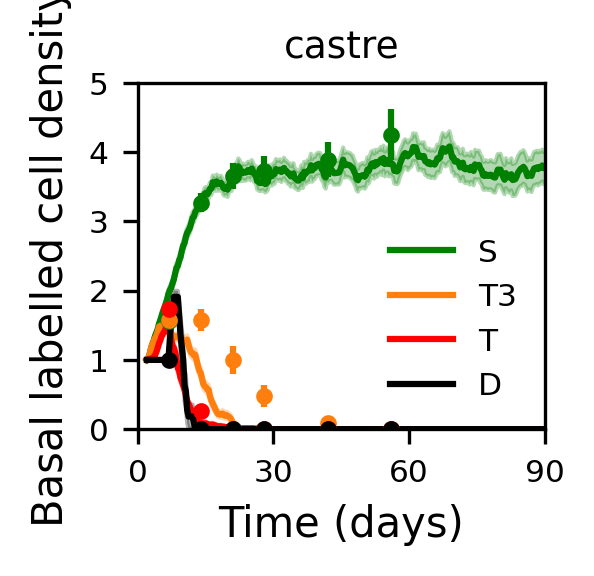

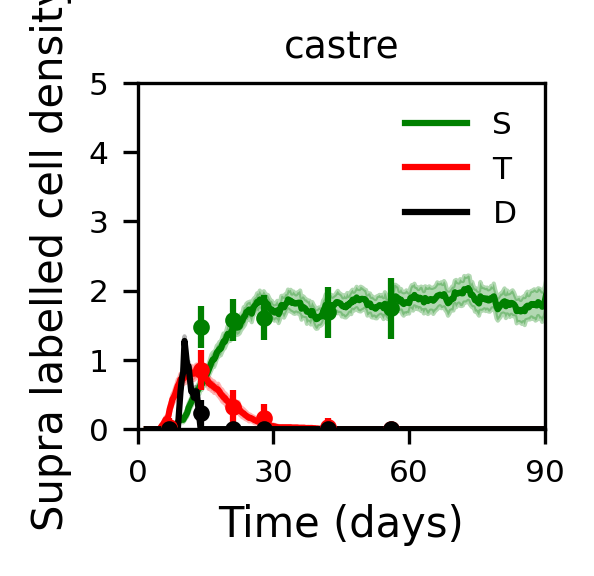

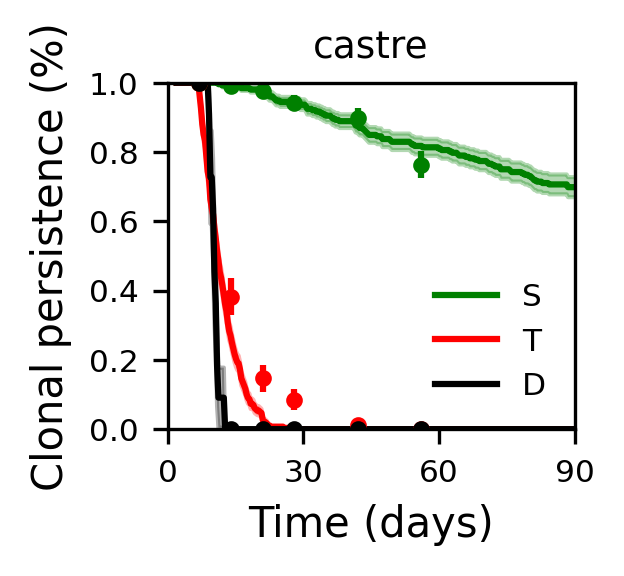

Already cropped


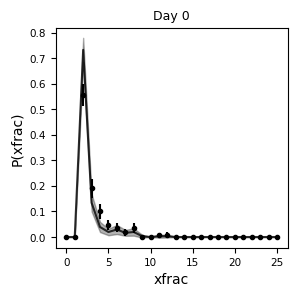




1 0 M
M 4454.550803712797 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_0.3_CVd_S_0.5_CVd_T_-1.0_corrDD_0.4_corrSS_0.3_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_0.5_r_0.1_refractT_-1.0_rhoS_0.3_tau_100.0_seed_0.pkl
tscale: -6.65
τ range: 4.6 to 140.0
shed: -0.5 refract: 0.0 cv: 1.0
Already cropped
Already cropped
Already cropped
Already cropped


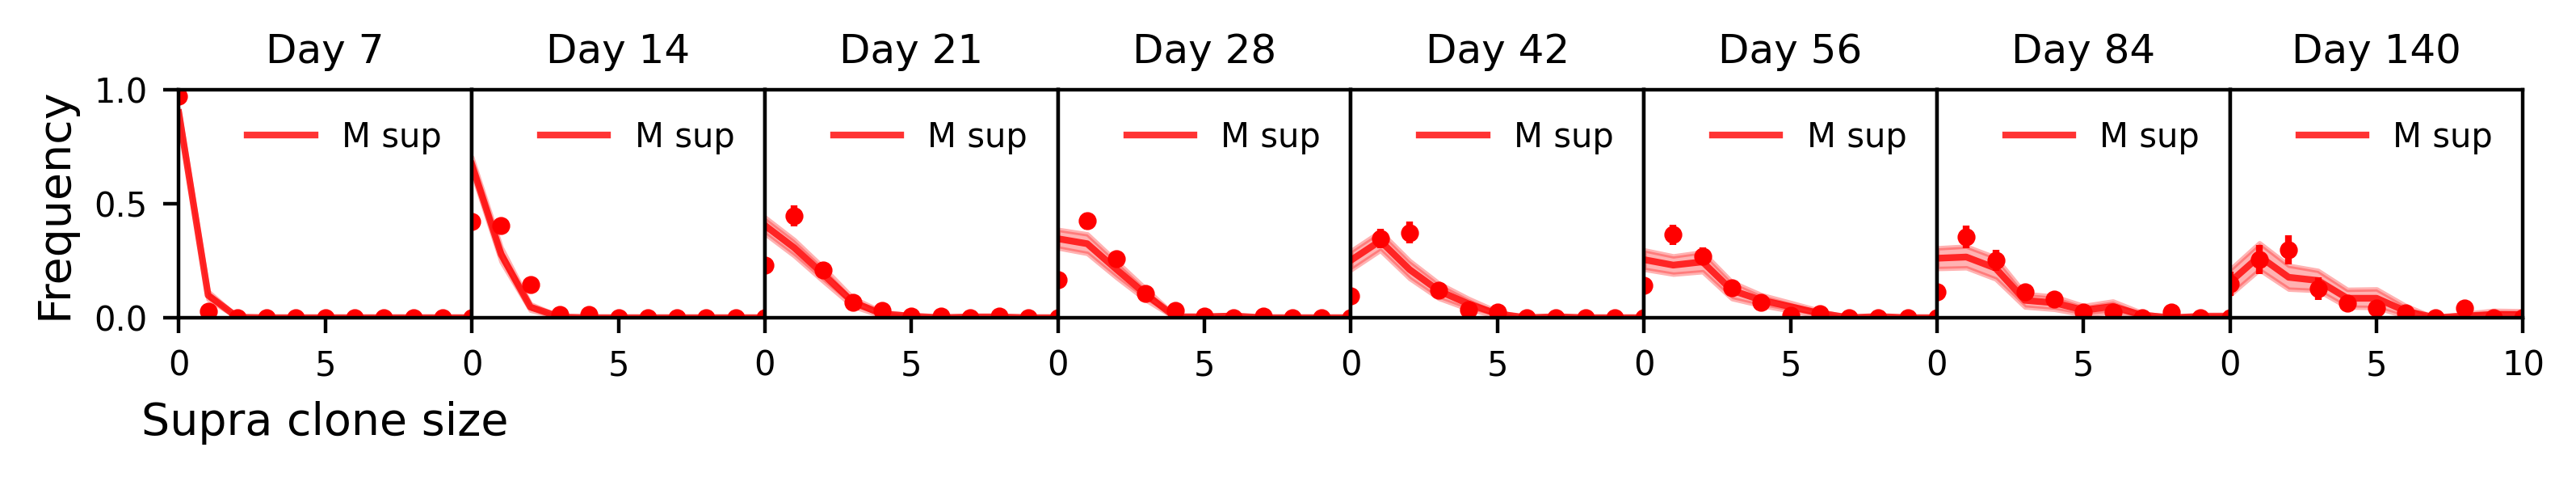

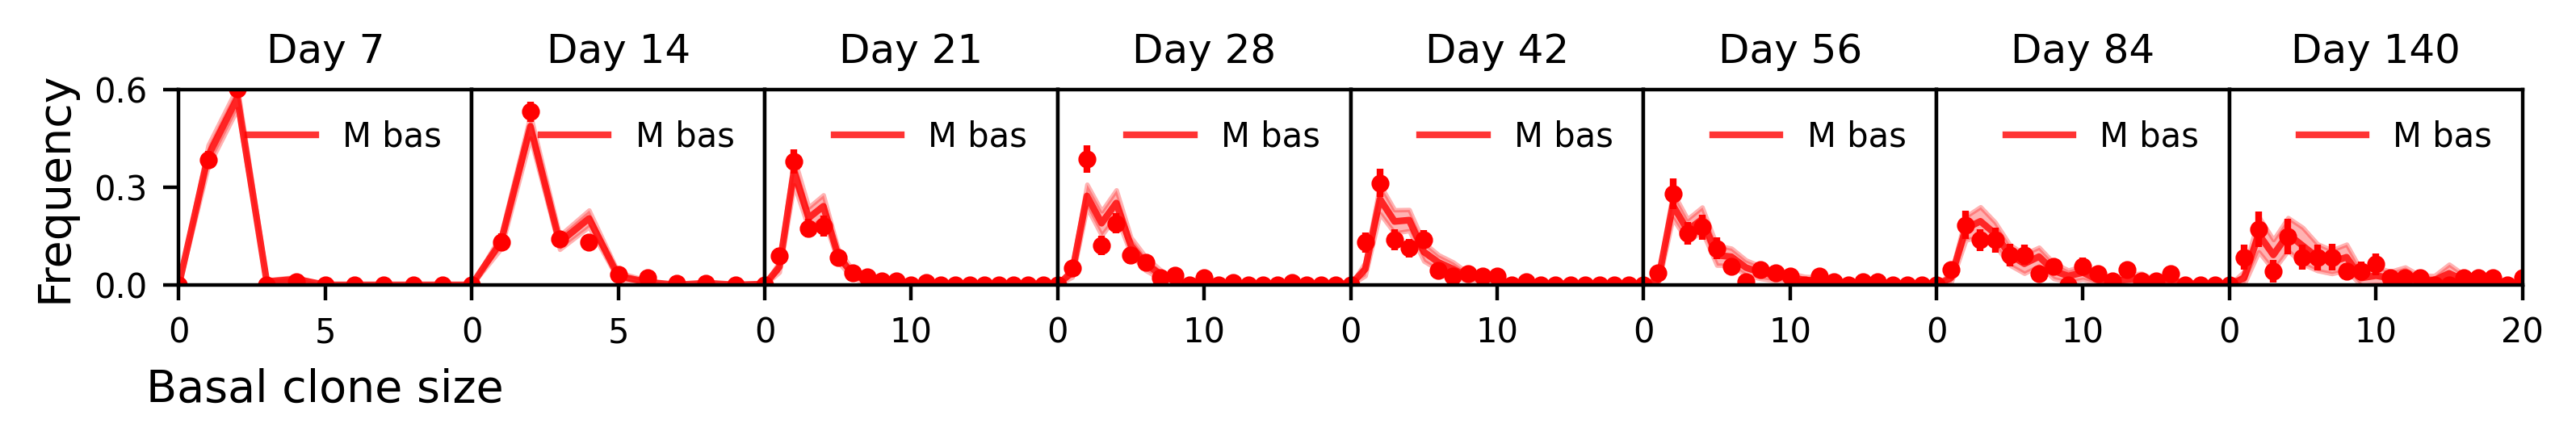

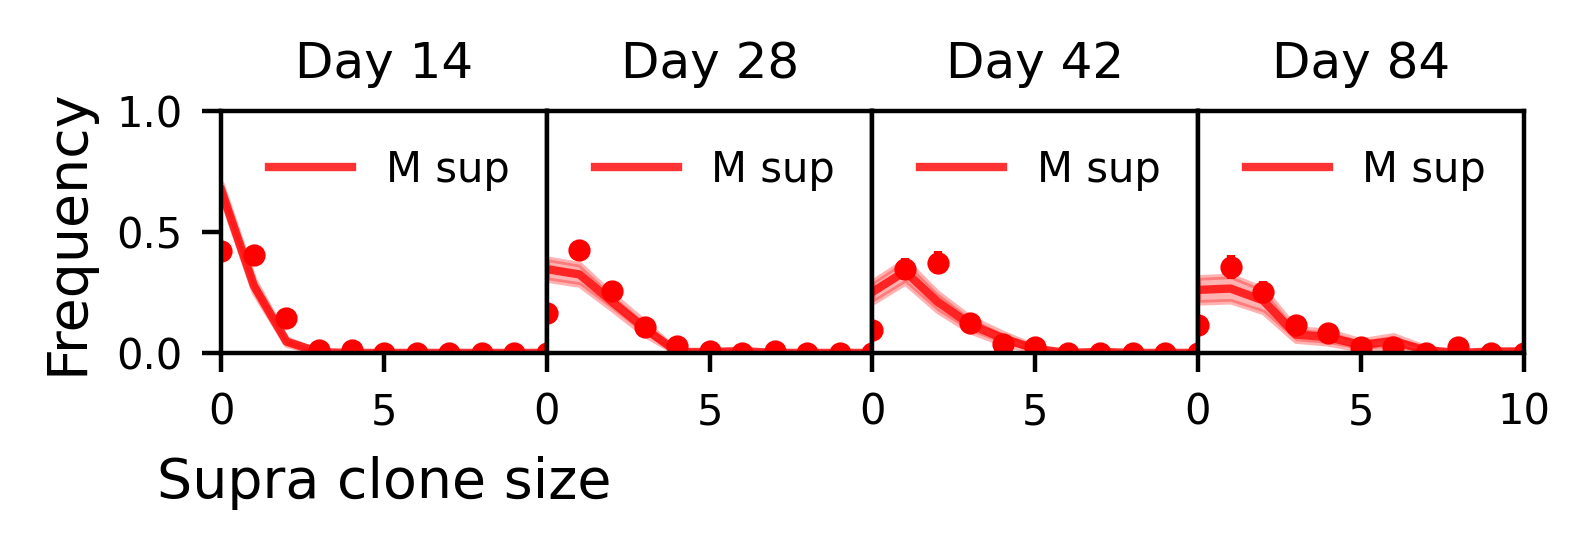

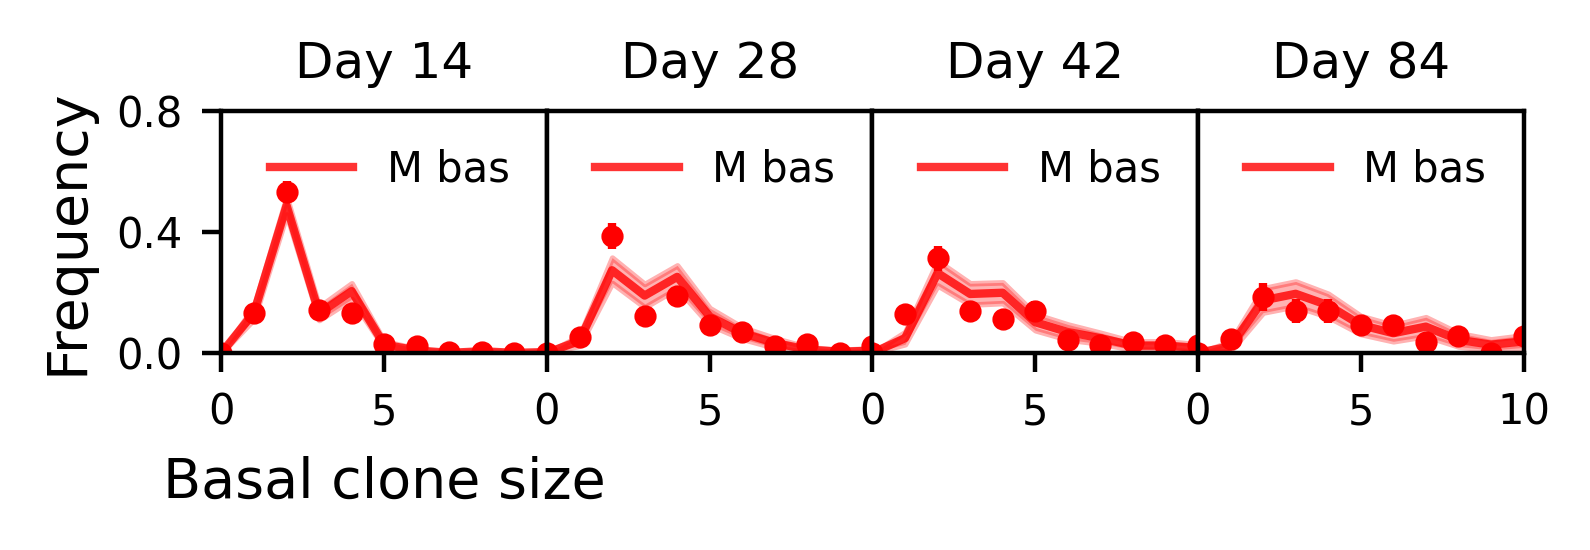

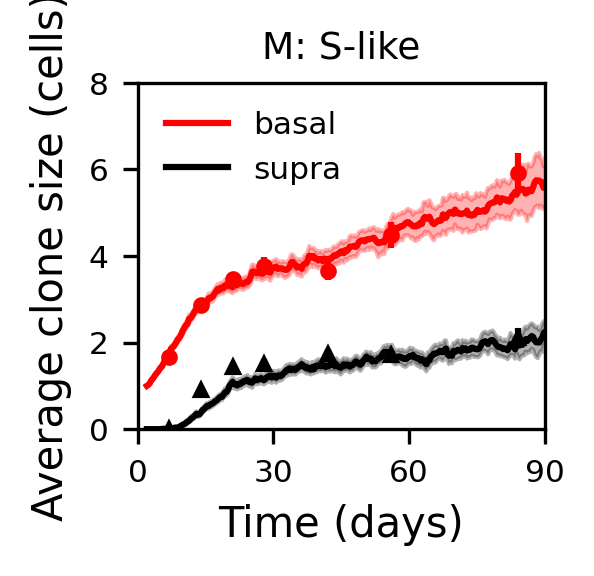

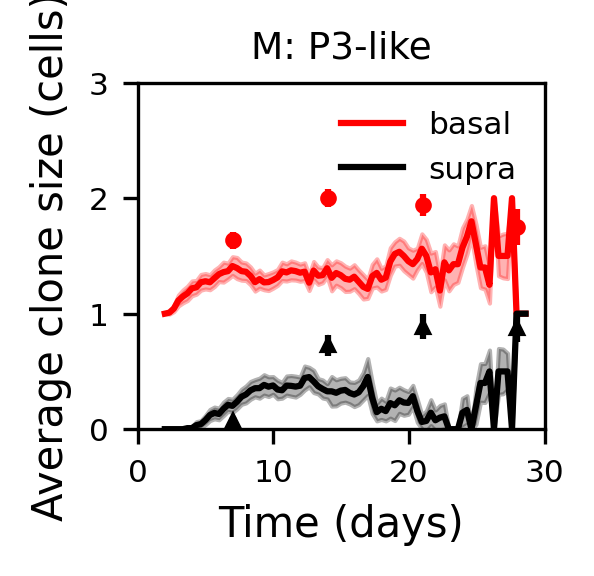

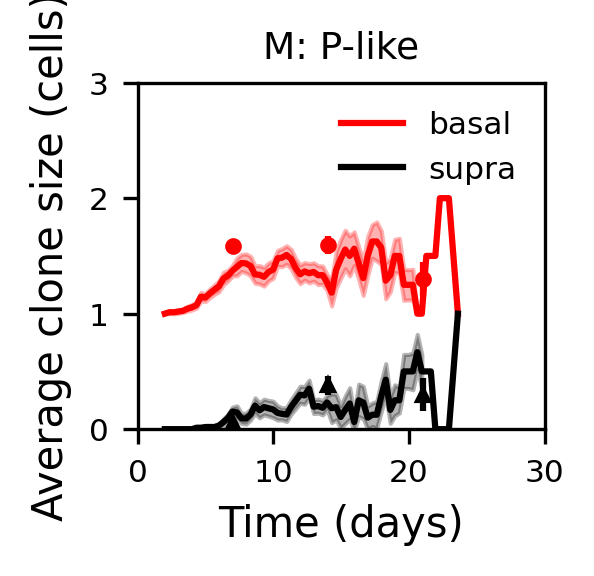

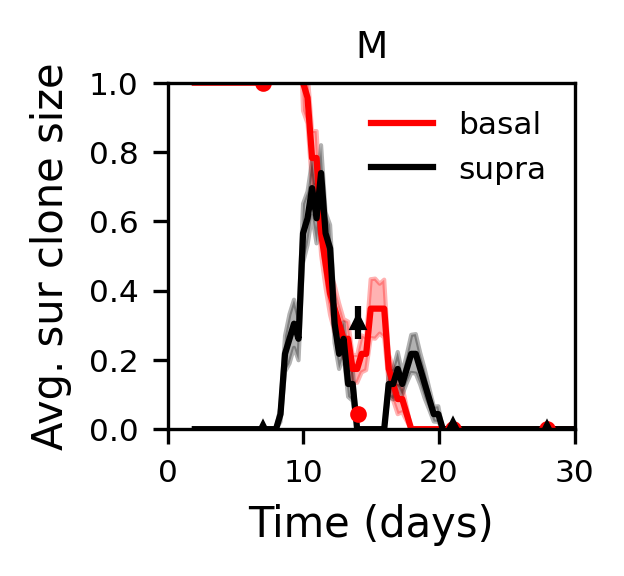

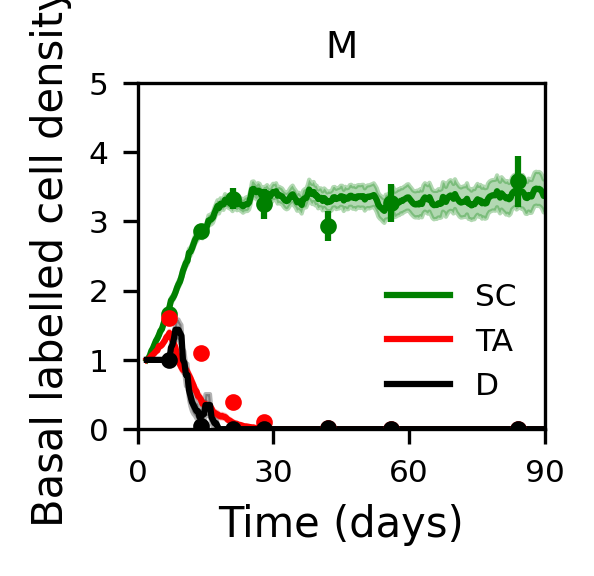

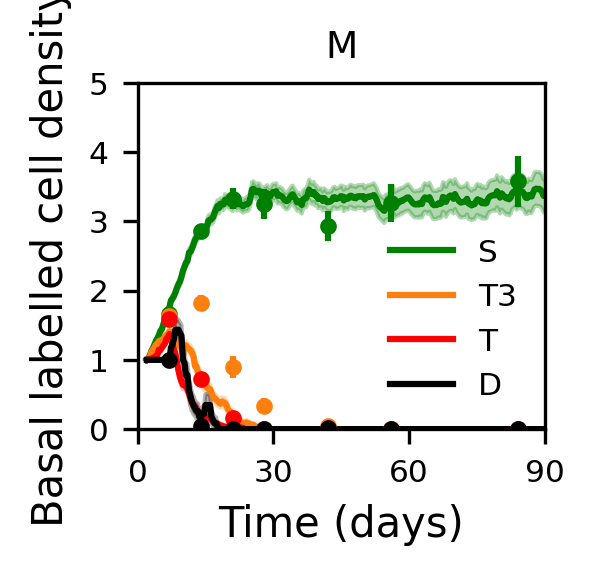

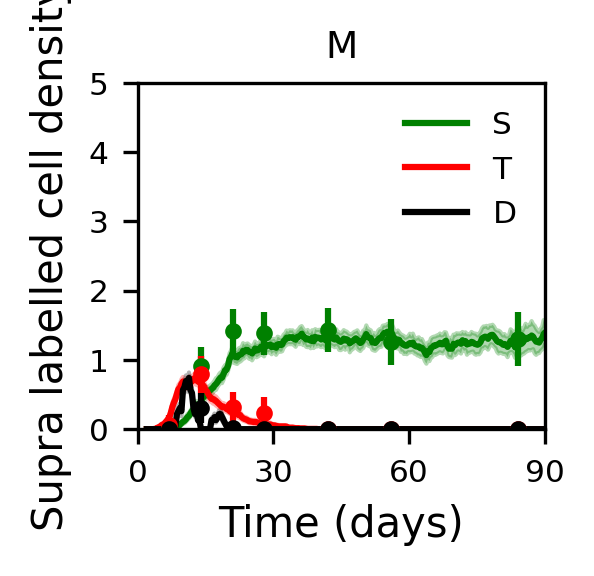

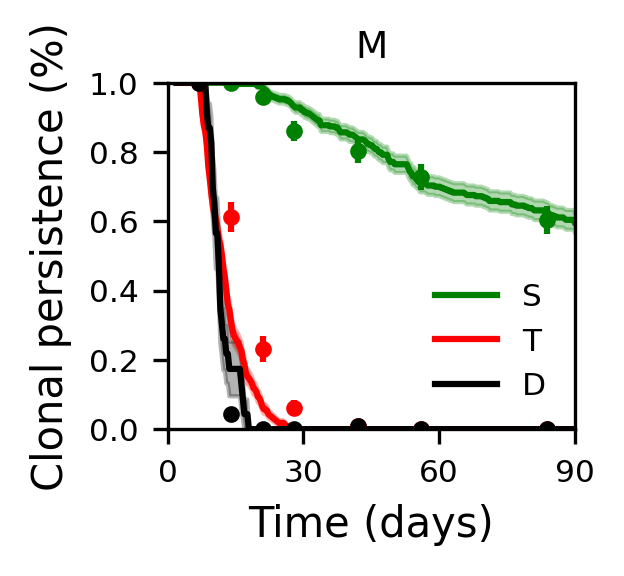

Already cropped


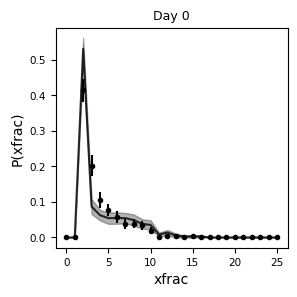




M 1.501824452938345 ksd_b_sb
hrun_ST2D_0D_t_-30_n_1000_CVd_D_0.5_CVd_S_0.5_CVd_T_-1.0_corrDD_0.7_corrSS_0.3_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_0.5_r_0.05_refractT_-1.0_rhoS_0.3_tau_100.0_seed_0.pkl
tscale: -6.0
τ range: 4.6 to 140.0
shed: -0.6 refract: 0.0 cv: 1.0
Already cropped
Already cropped
Already cropped
Already cropped


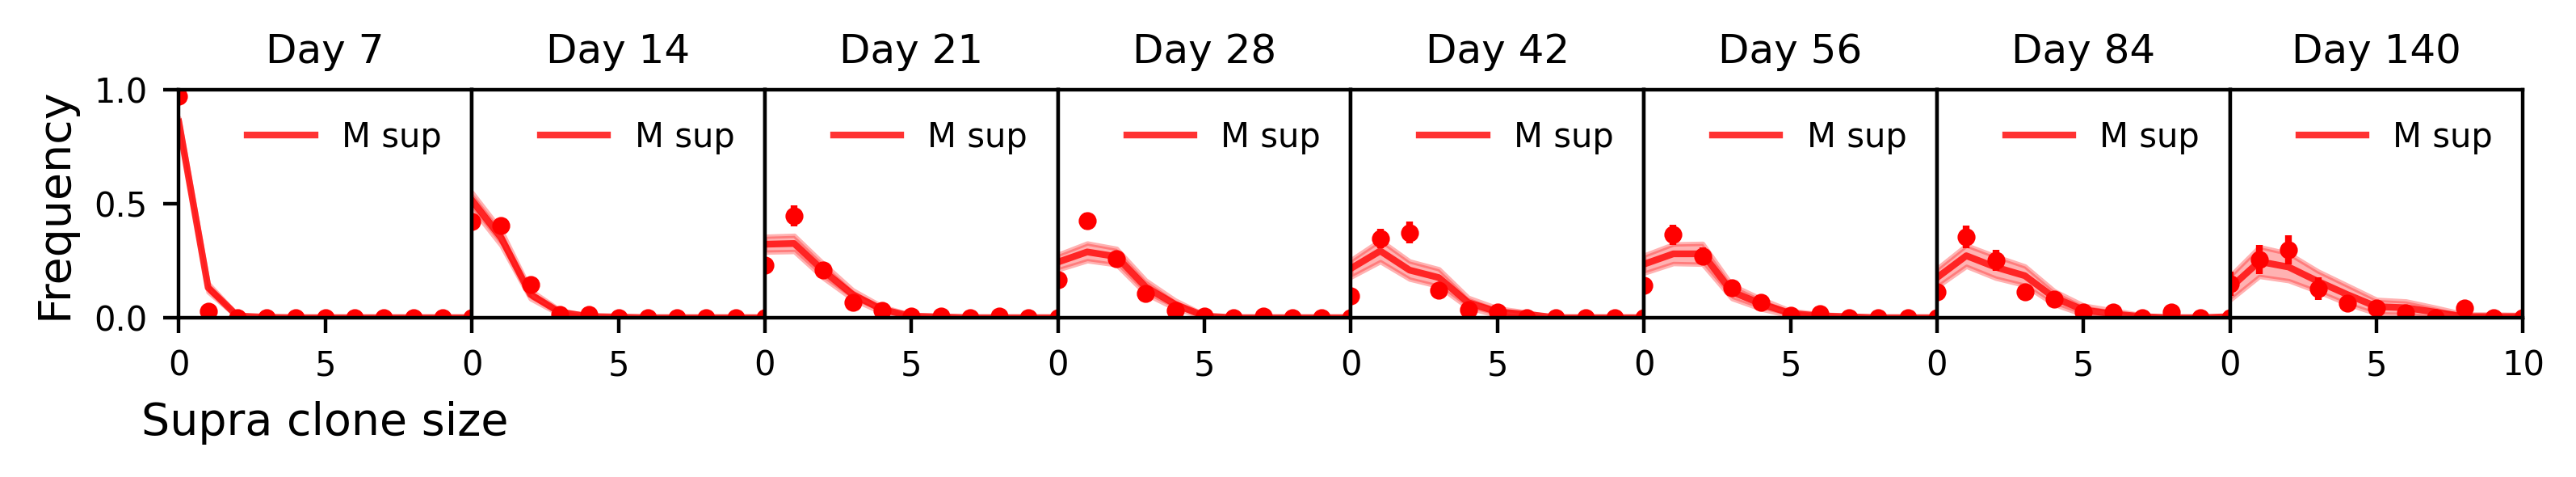

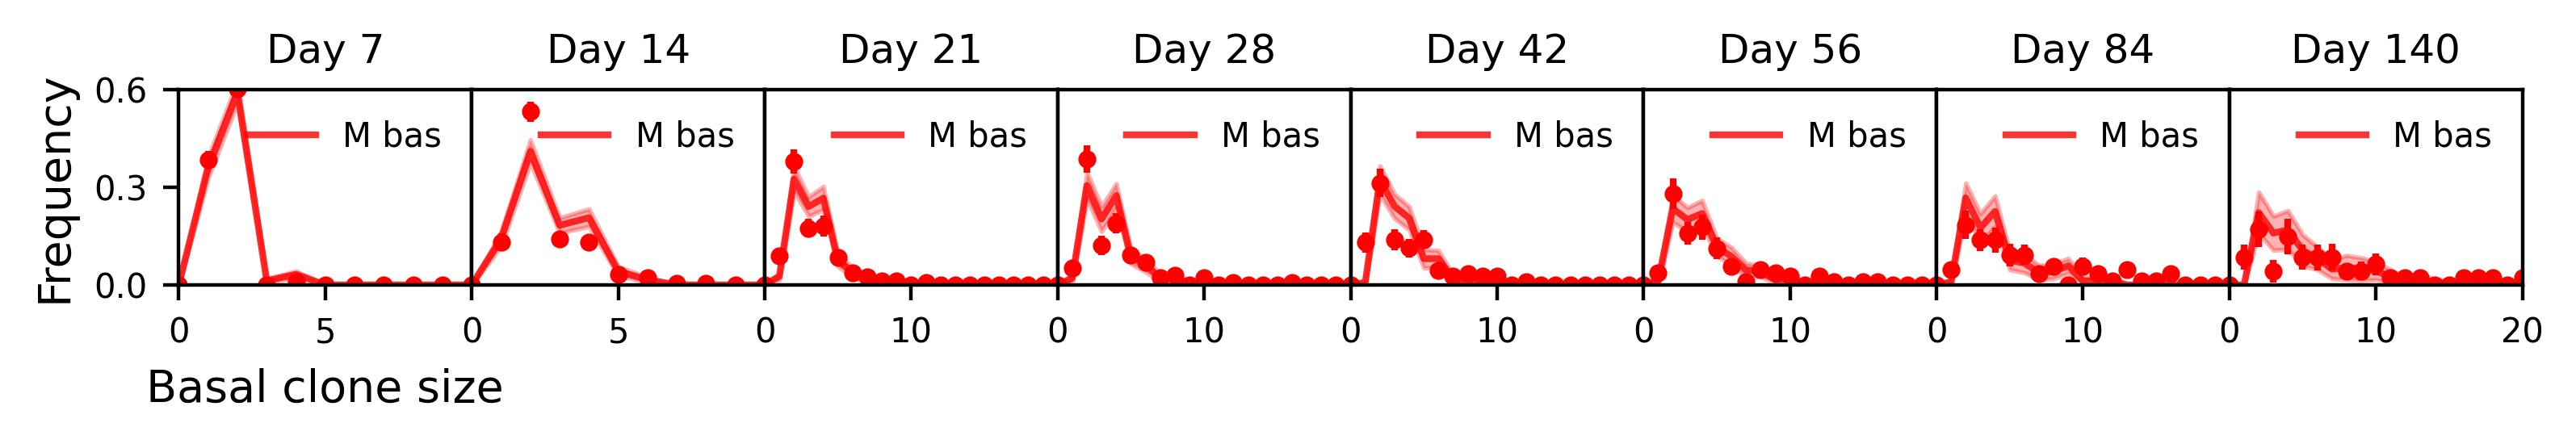

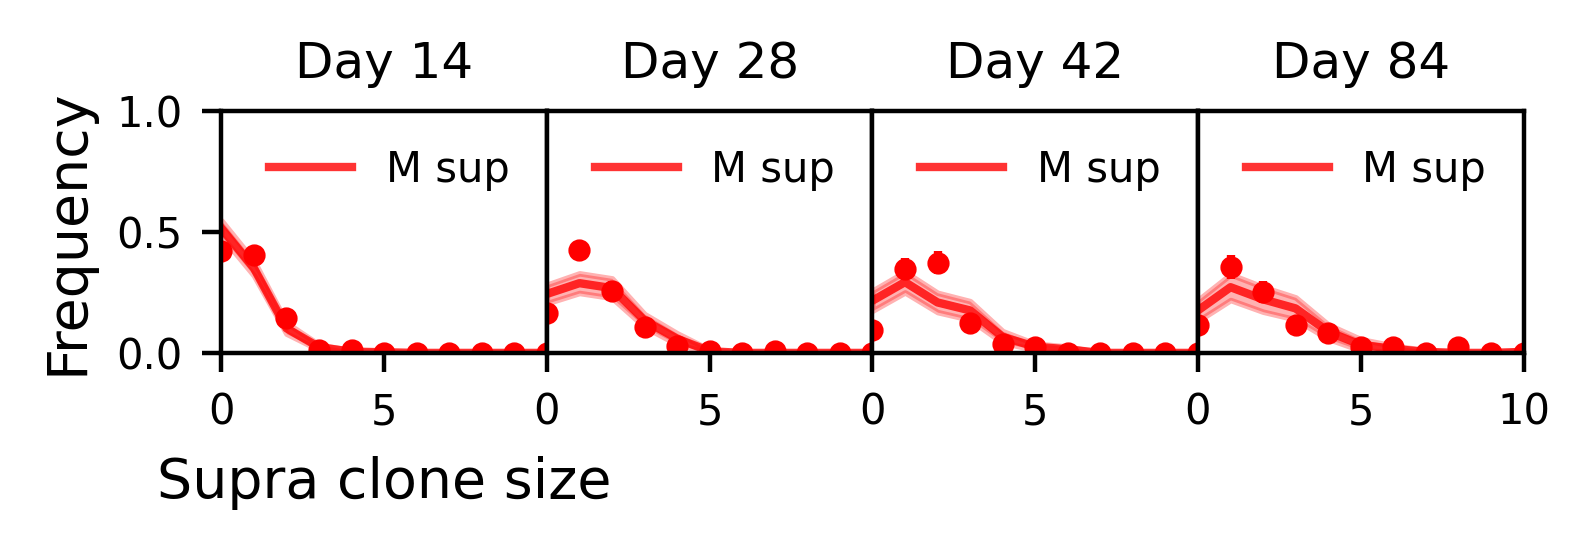

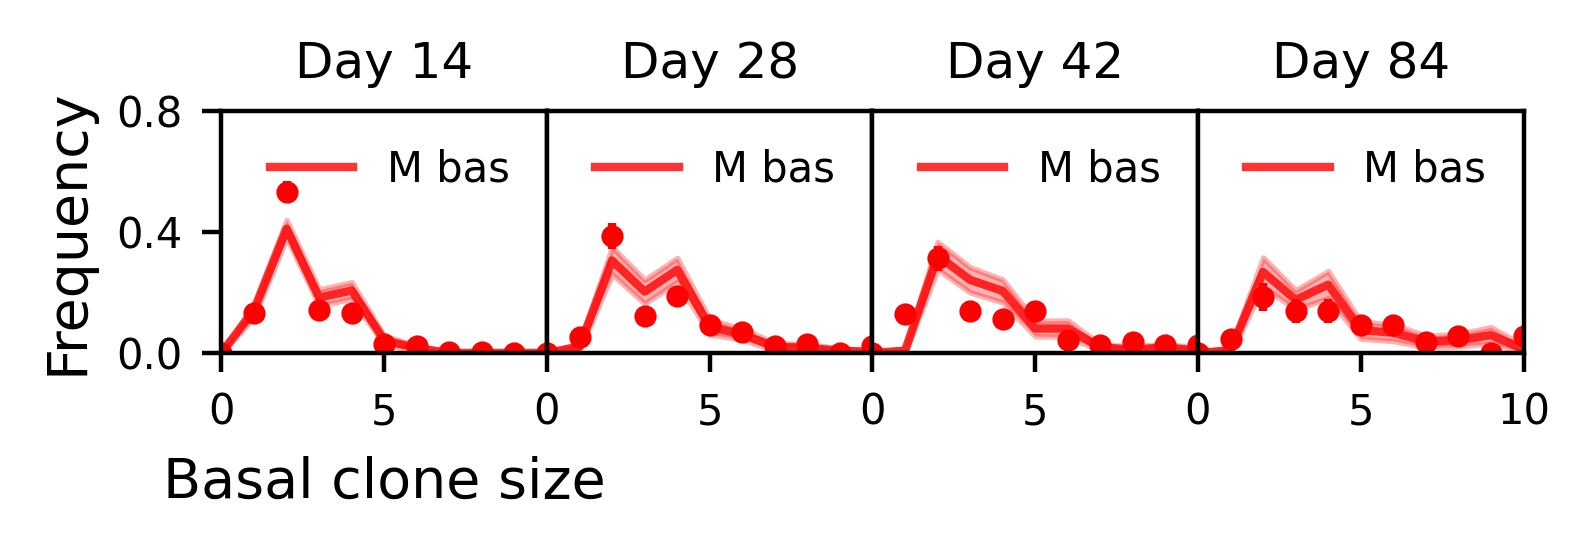

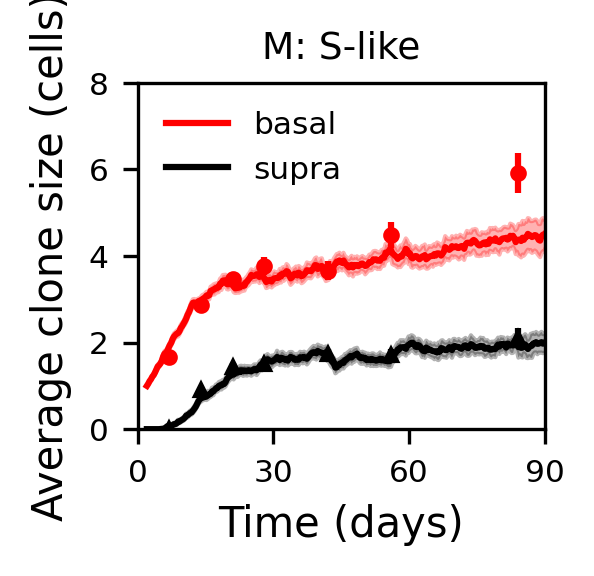

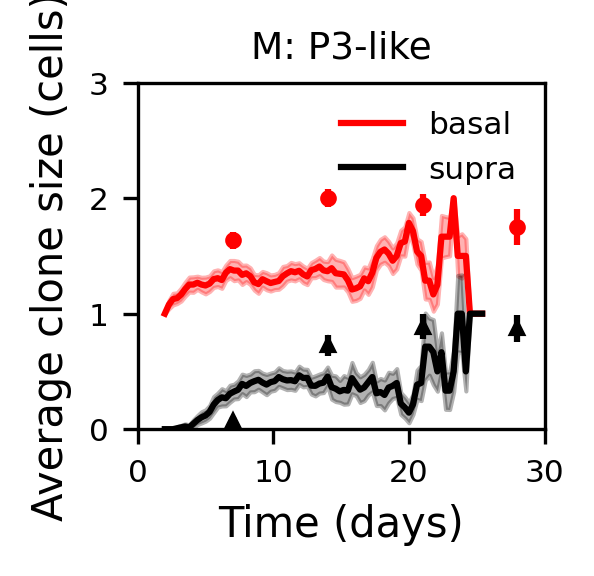

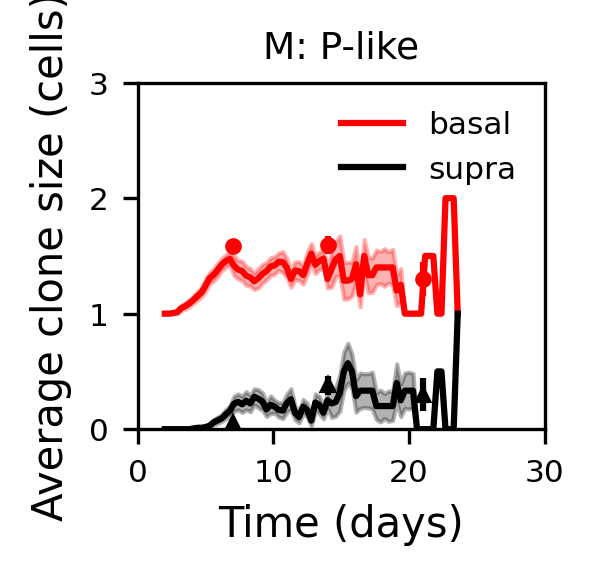

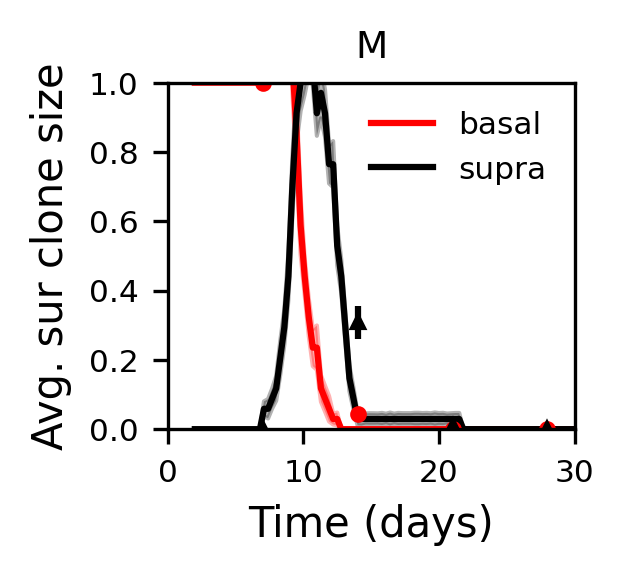

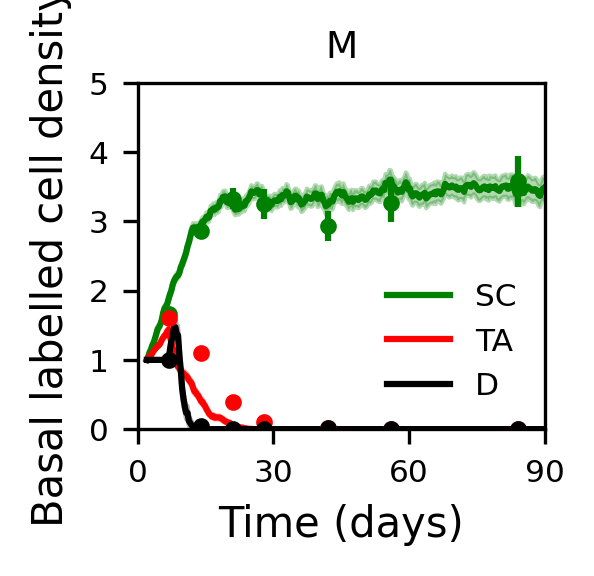

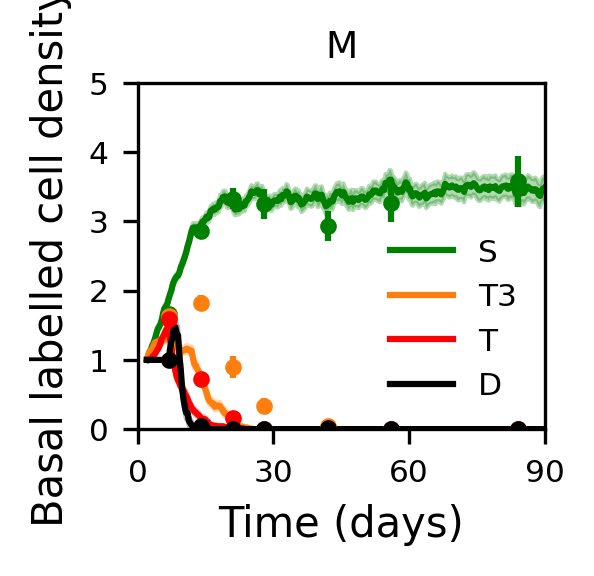

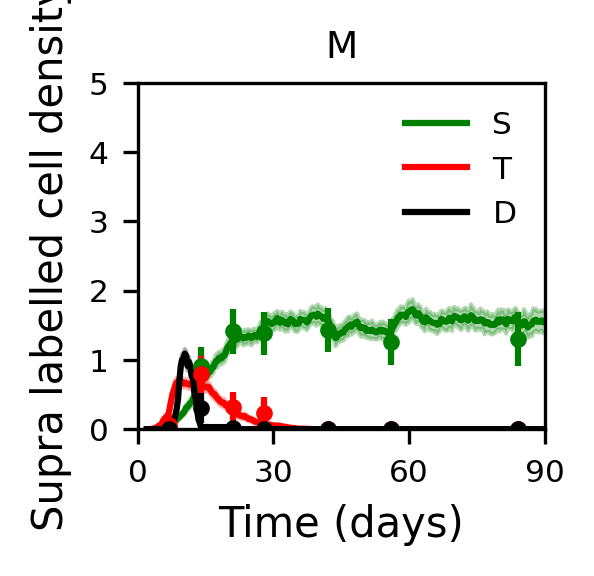

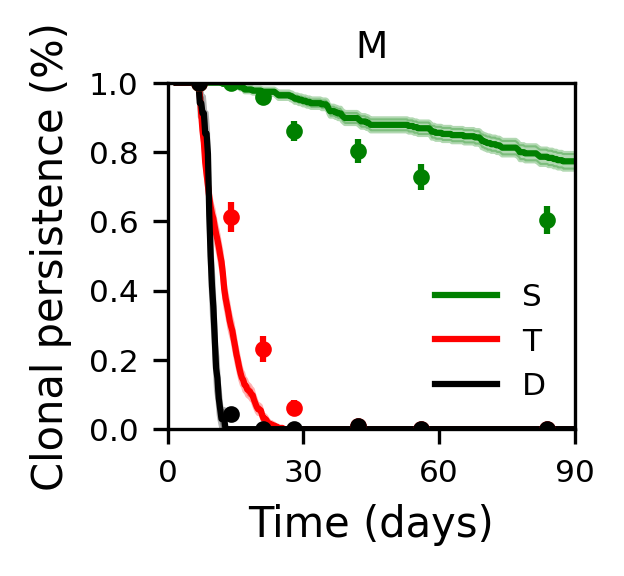

Already cropped


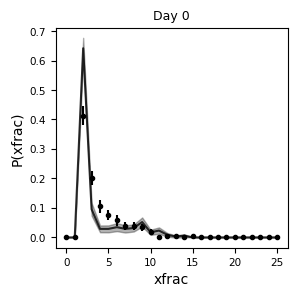




1 0 F
F 10238.392052223677 ll_SPD
hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_0.5_CVd_T_-1.0_corrDD_0.8_corrSS_0.9_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_1.0_r_0.15_refractT_-1.0_rhoS_0.275_tau_100.0_seed_0.pkl
tscale: -6.3
τ range: 4.6 to 140.0
shed: -0.85 refract: 0.0 cv: 0.1
Already cropped
Already cropped
Already cropped
Already cropped


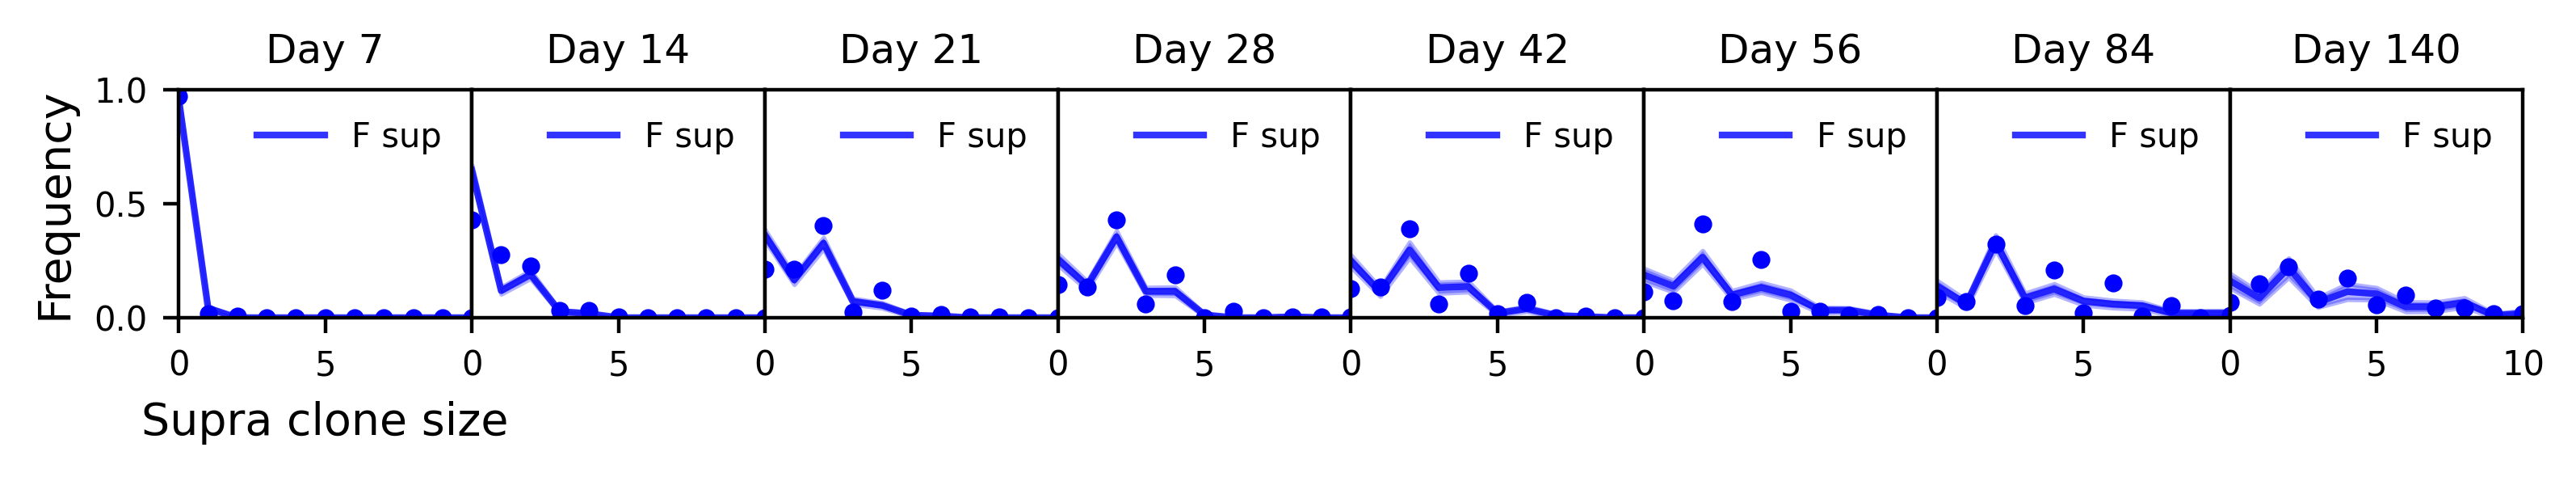

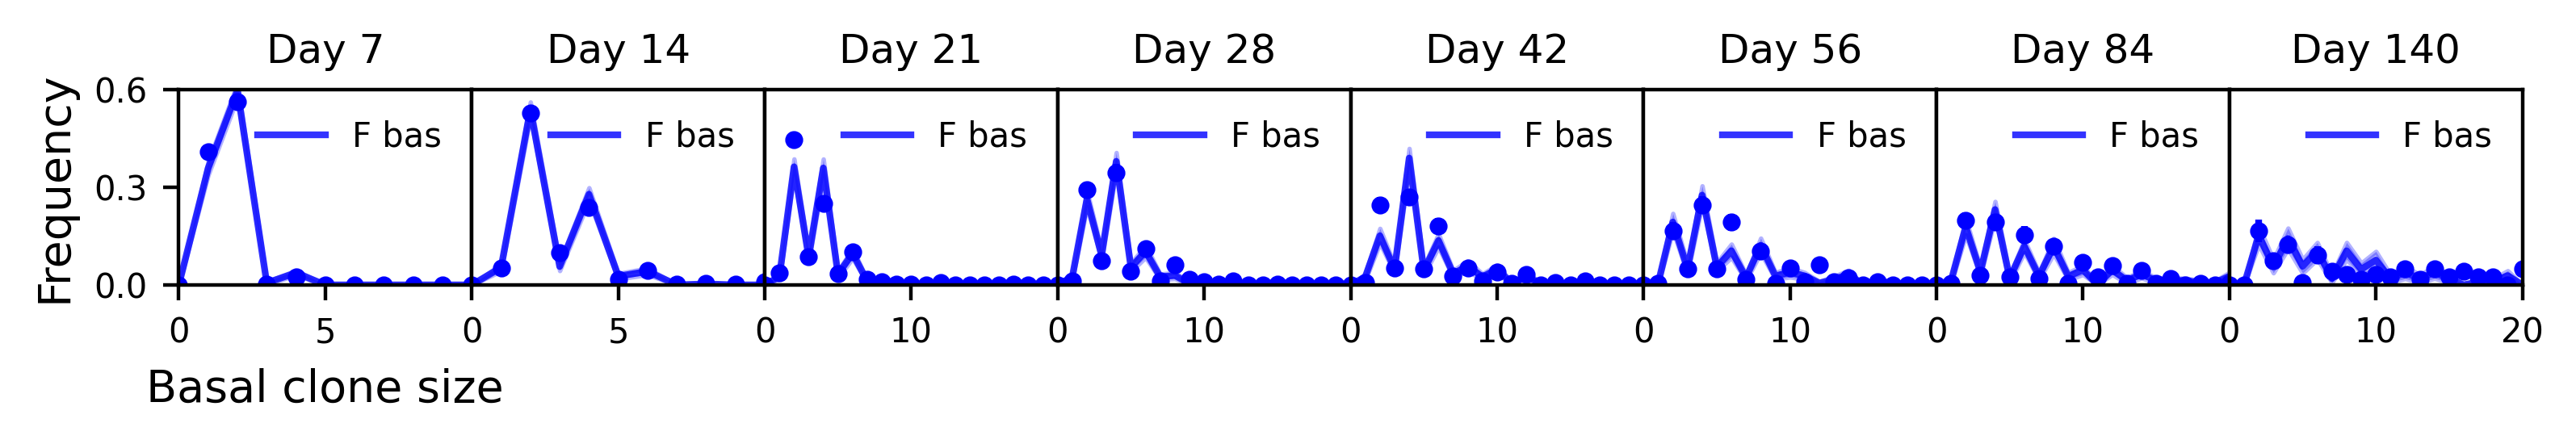

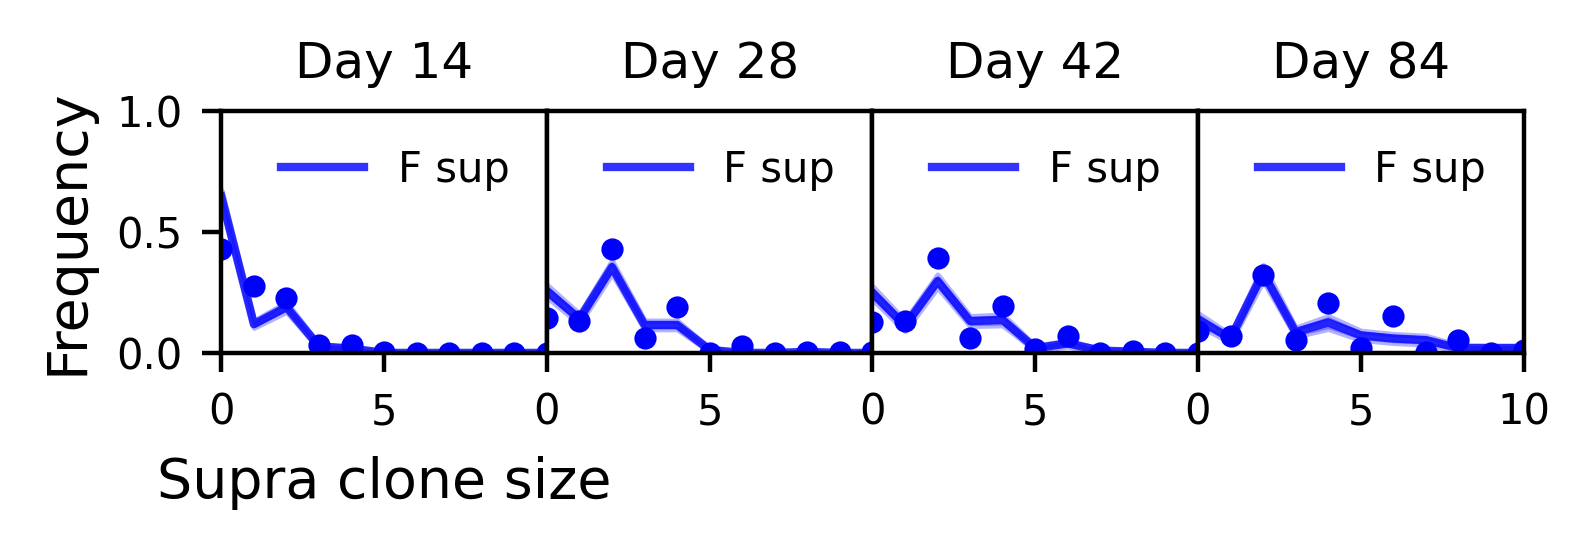

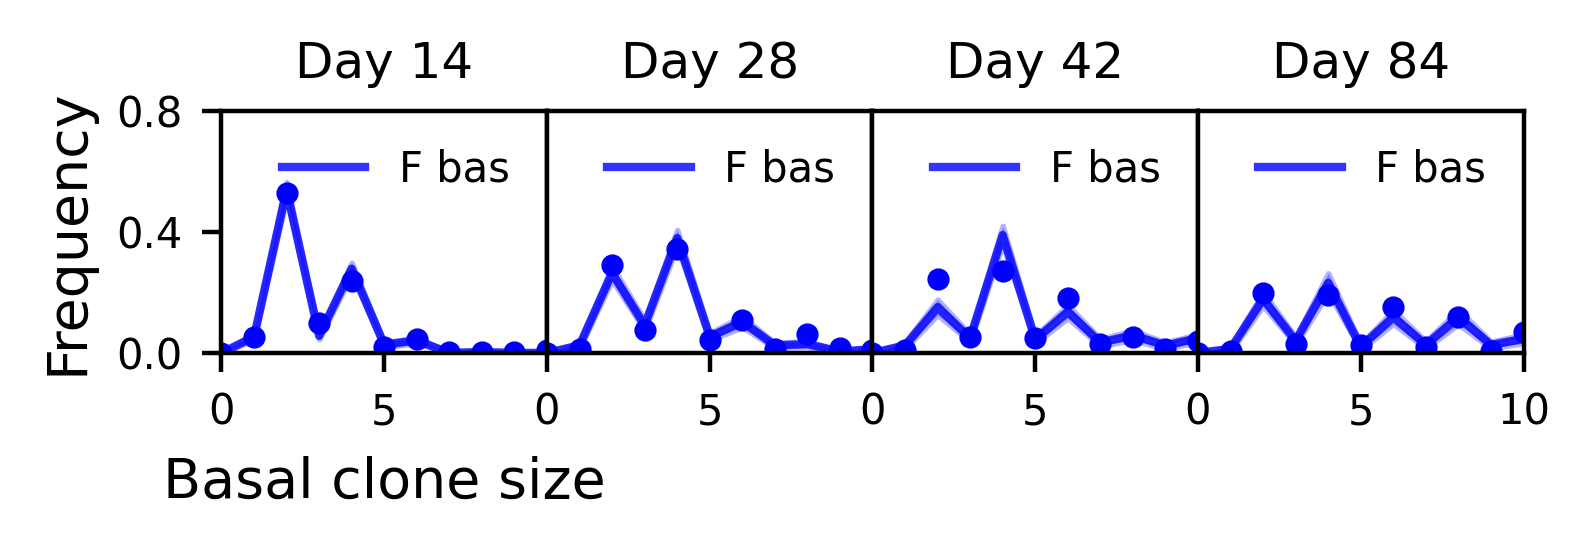

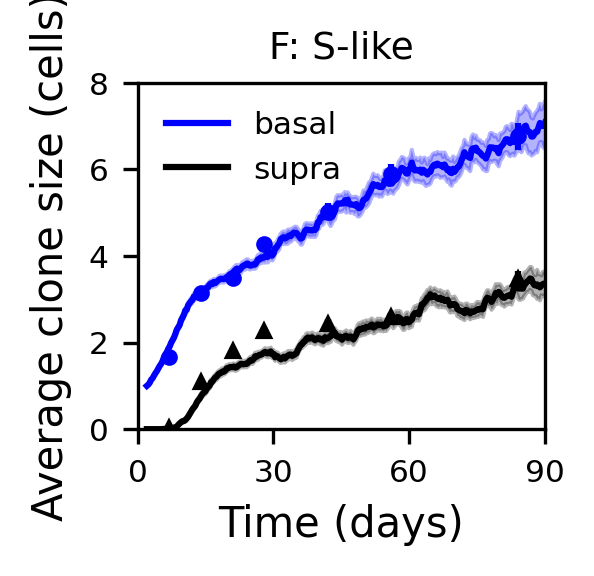

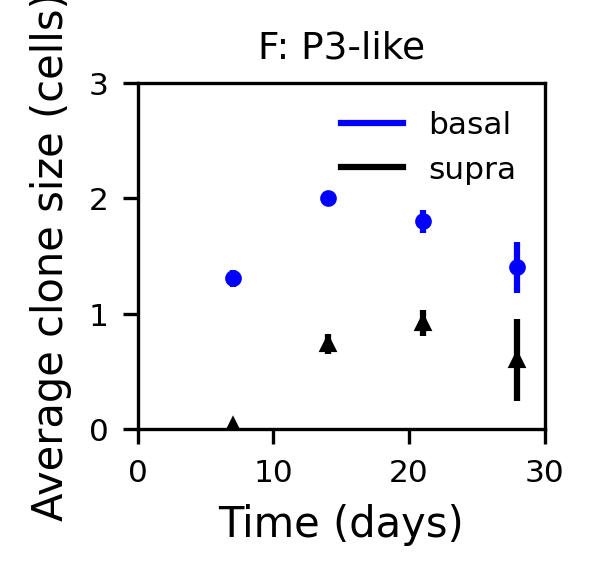

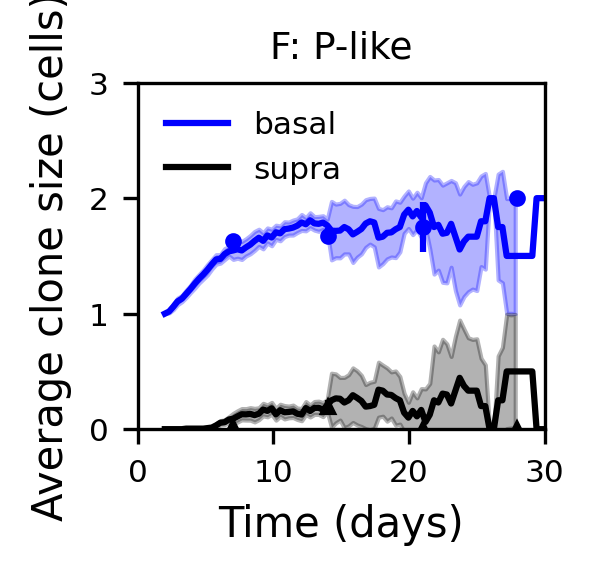

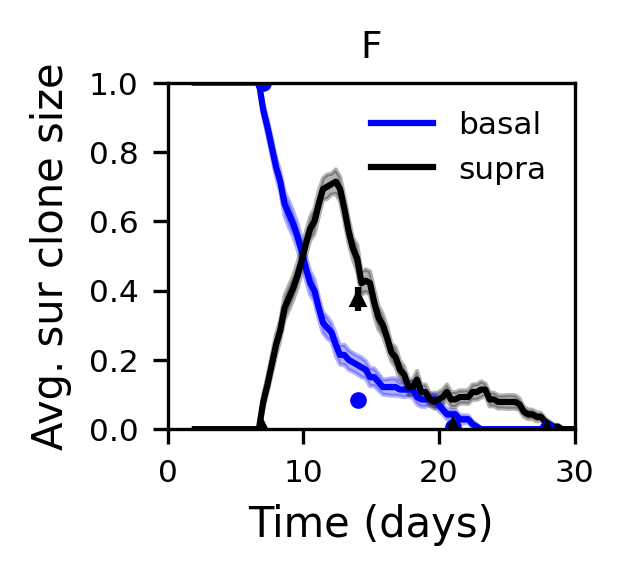

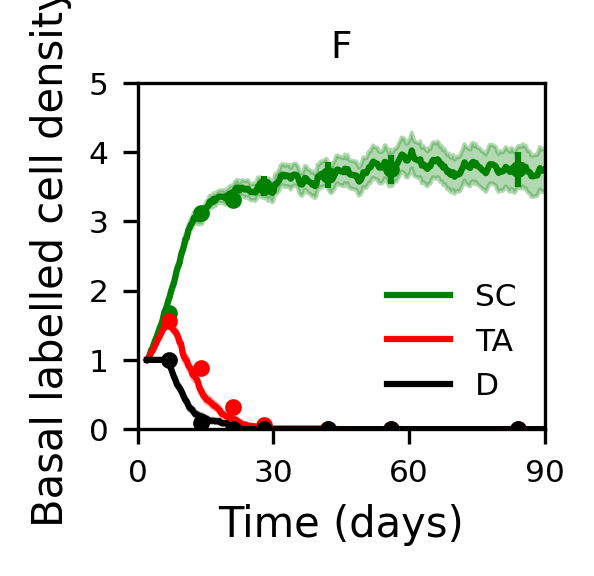

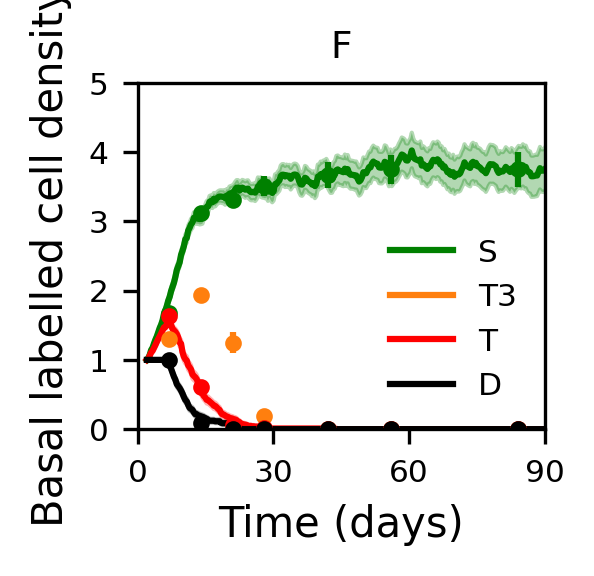

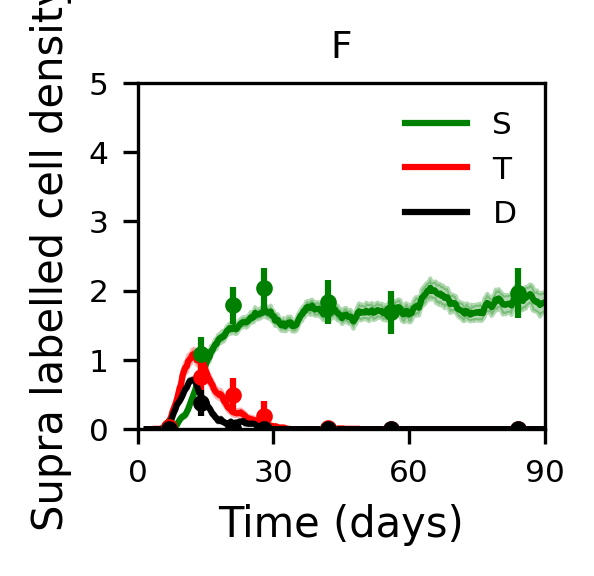

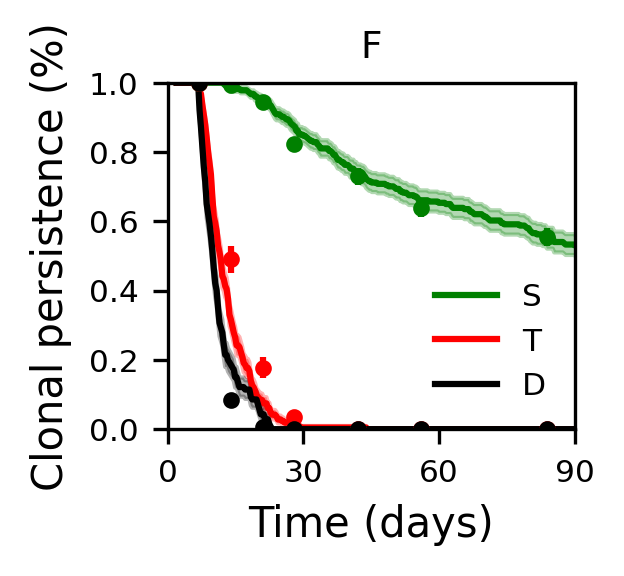

Already cropped


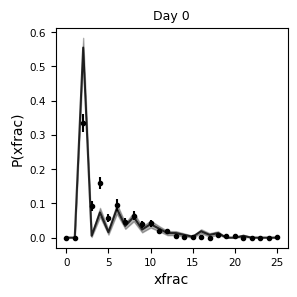




F 1.421629486068408 ksd_b_sb
hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_0.5_CVd_T_-1.0_corrDD_0.8_corrSS_0.9_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_1.0_r_0.15_refractT_-1.0_rhoS_0.275_tau_100.0_seed_0.pkl
tscale: -6.3
τ range: 4.6 to 140.0
shed: -0.9 refract: 0.0 cv: 0.1
Already cropped
Already cropped
Already cropped
Already cropped


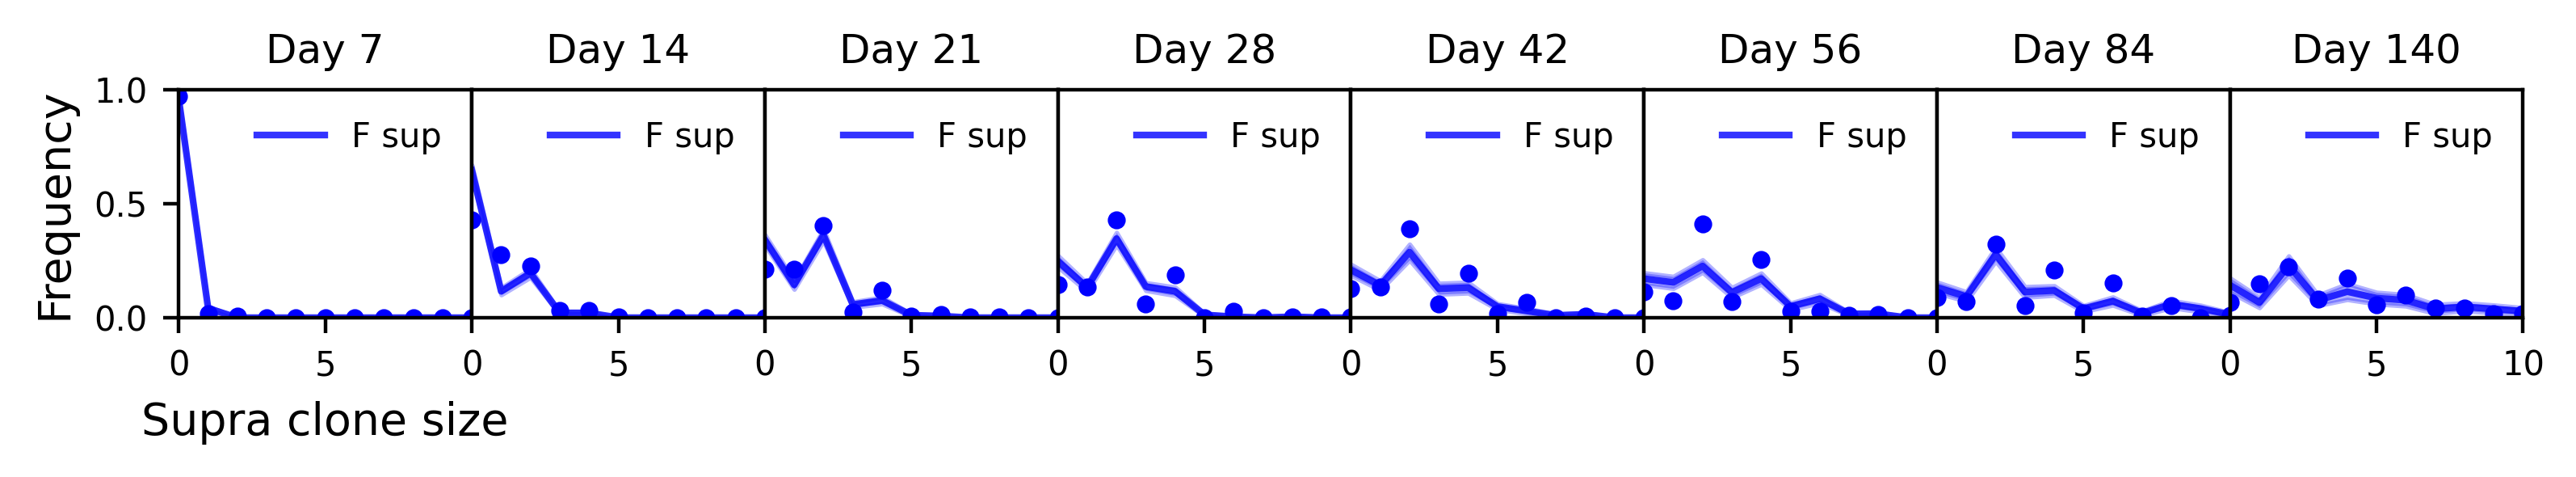

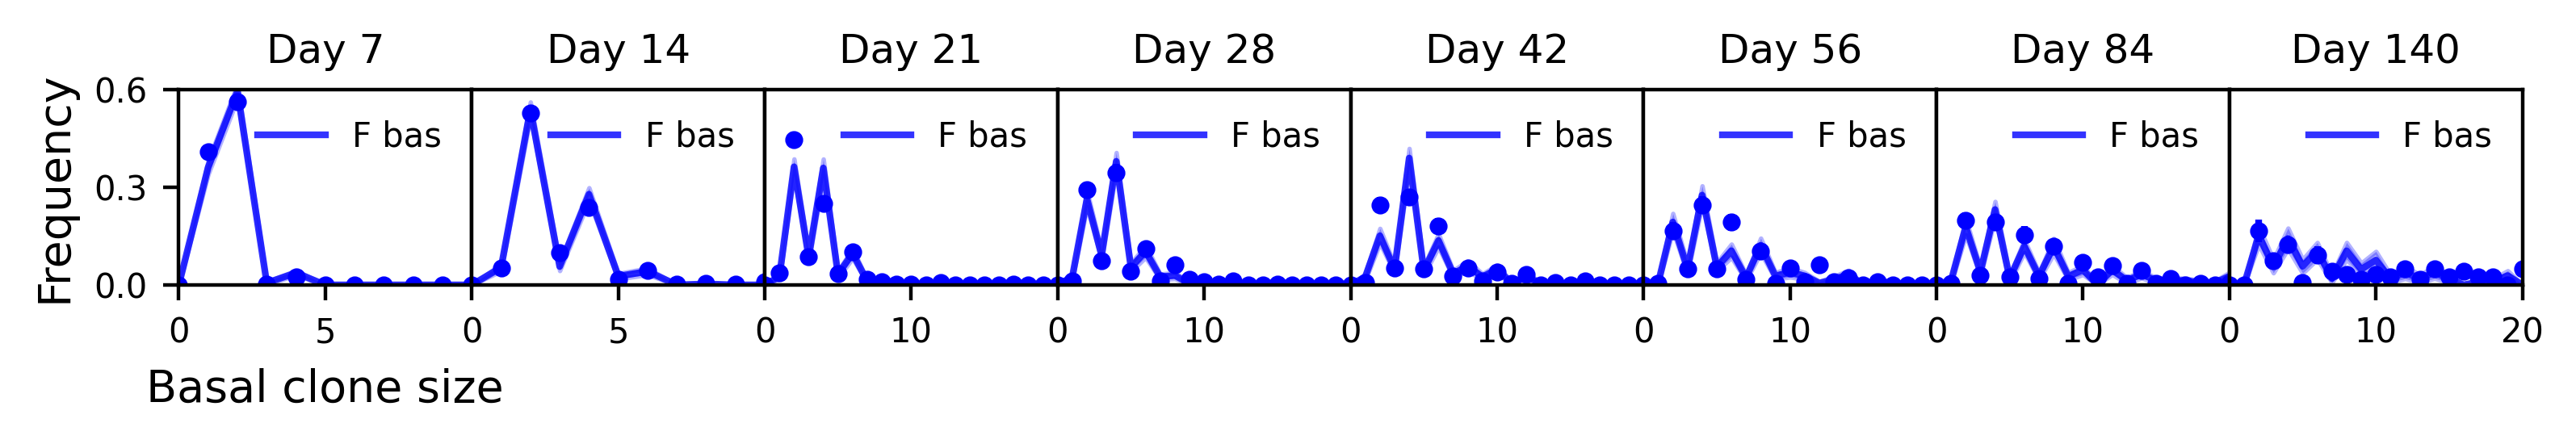

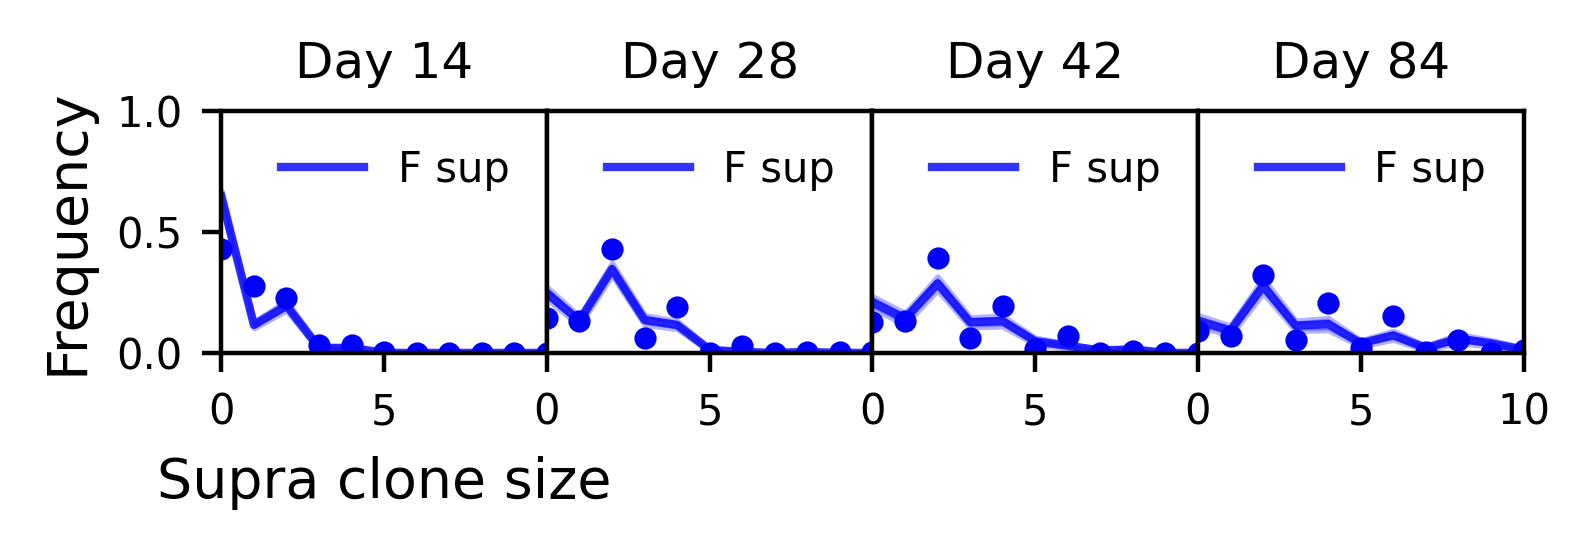

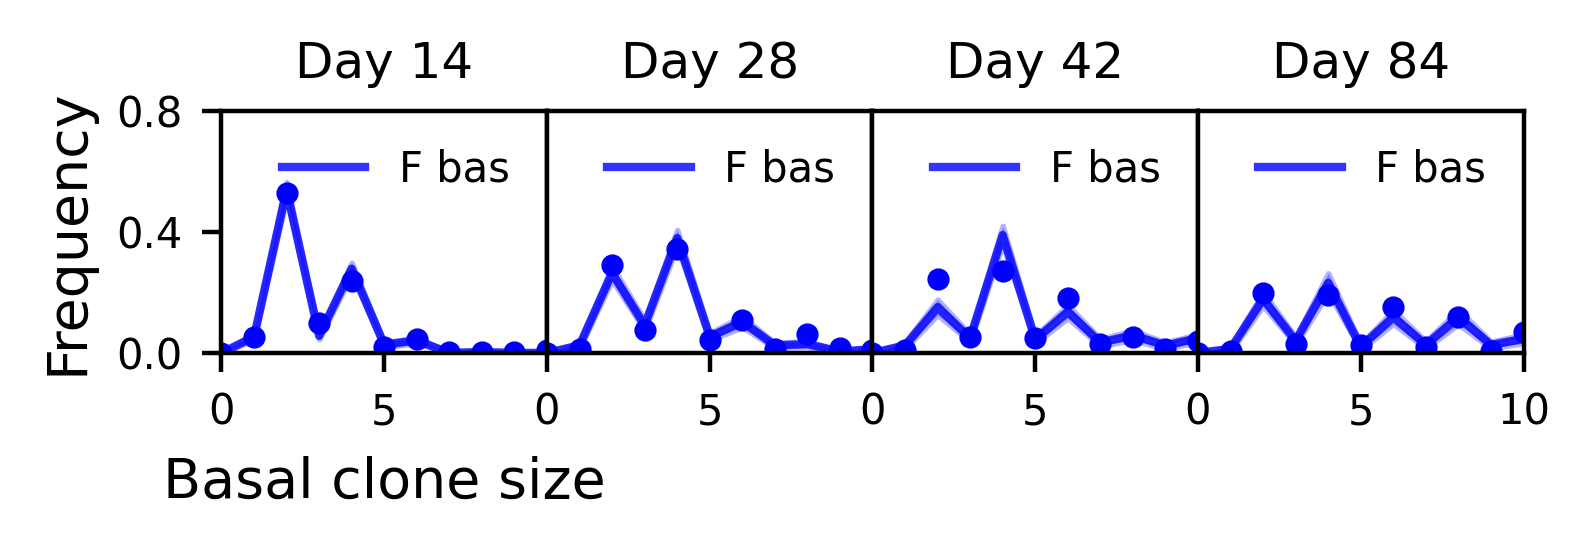

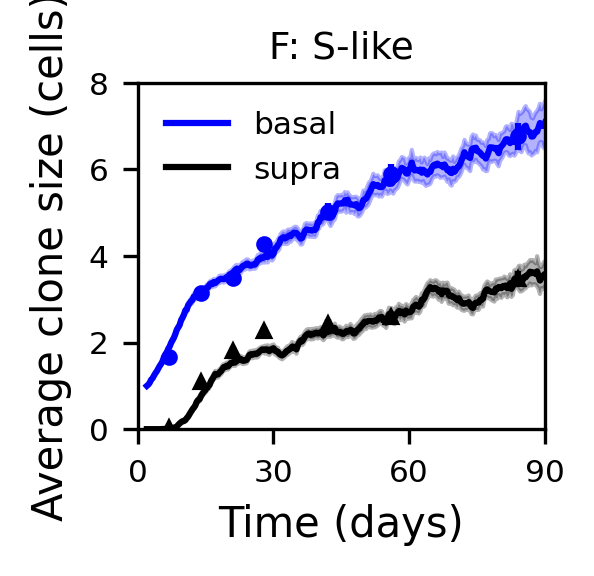

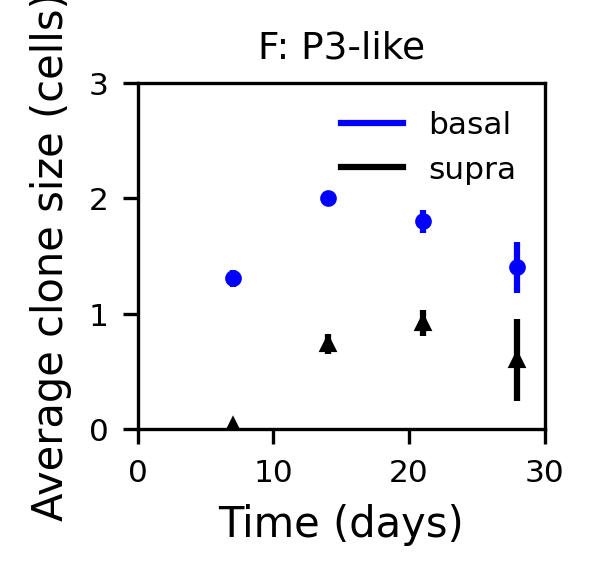

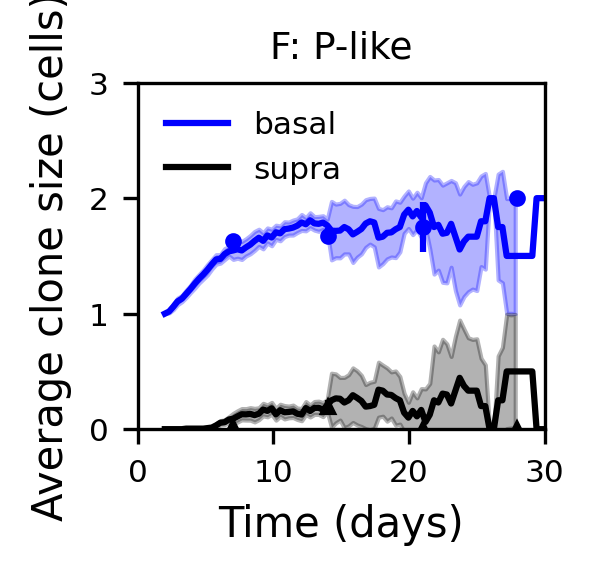

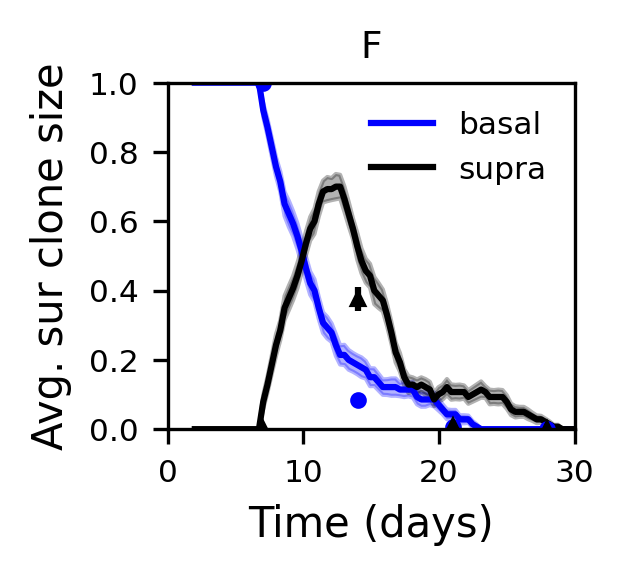

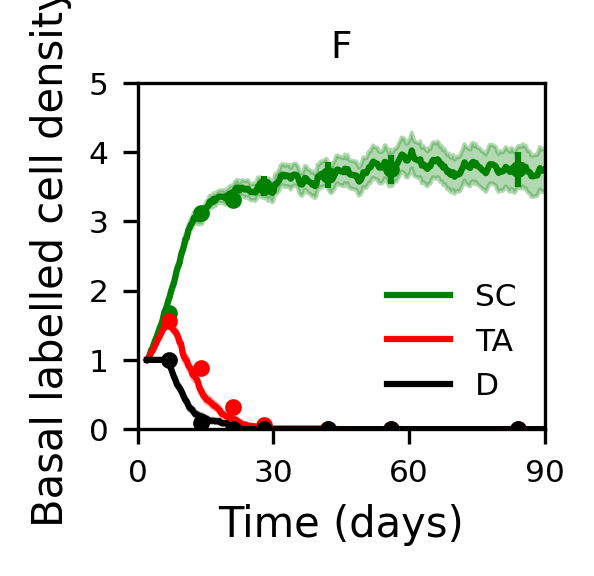

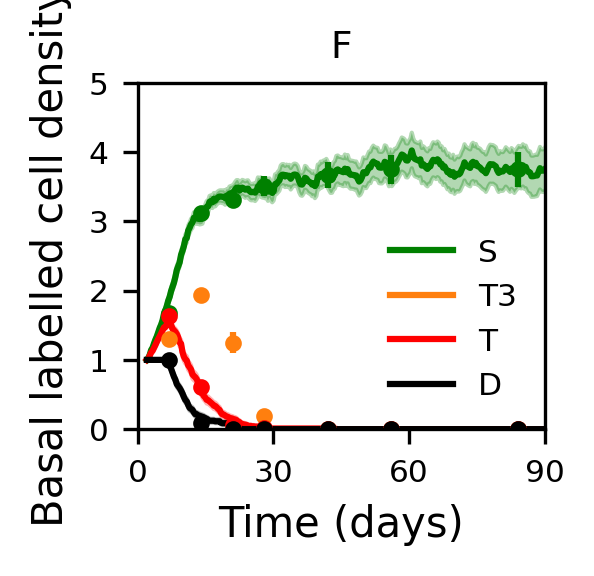

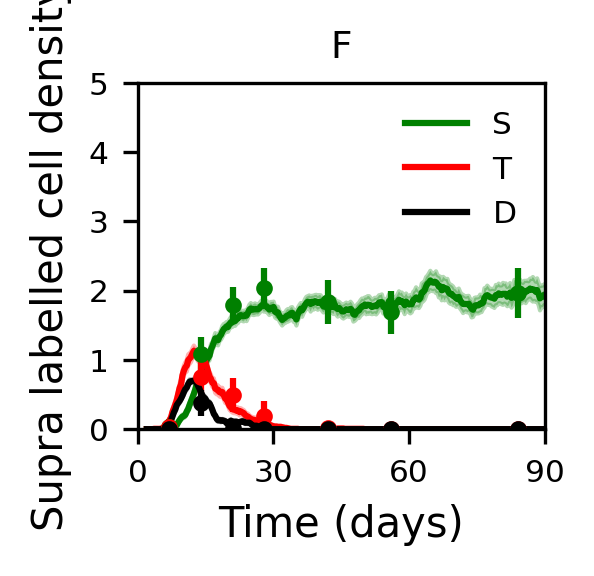

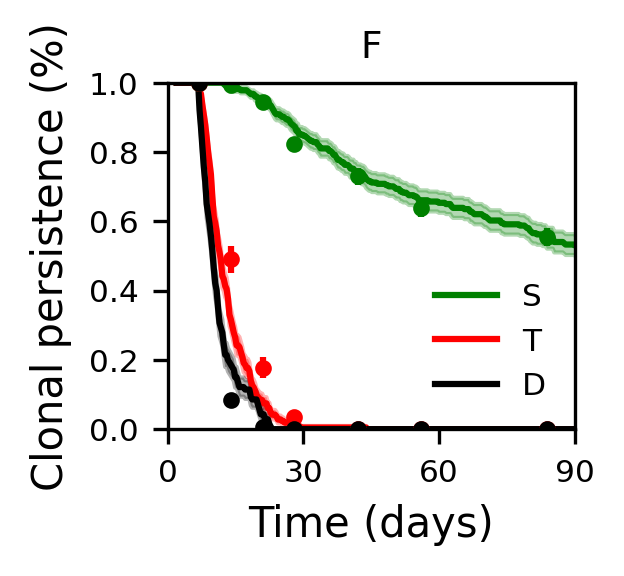

Already cropped


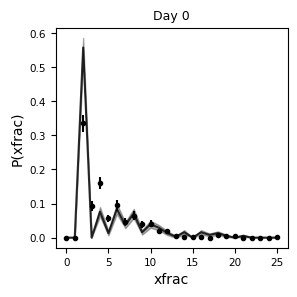








rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/ForPaper//modelling/ST2D_0D_finale//hrun_ST2D_0D_t_-30_n_1000_CVd_D_1.0_CVd_S_0.5_CVd_T_-1.0_corrDD_1.0_corrSS_0.5_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_0.5_r_0.075_refractT_-1.0_rhoS_0.275_tau_100.0_seed_0.pkl ./modelling/ST2D_0D_finale/ &
rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/ForPaper//modelling/ST2D_0D_finale//hrun_ST2D_0D_t_-30_n_1000_CVd_D_0.2_CVd_S_0.5_CVd_T_-1.0_corrDD_0.4_corrSS_0.3_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_0.5_r_0.075_refractT_-1.0_rhoS_0.275_tau_100.0_seed_0.pkl ./modelling/ST2D_0D_finale/ &
rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-D-model/ForPaper//modelling/ST2D_0D_finale//hrun_ST2D_0D_t_-30_n_1000_CVd_D_0.3_CVd_S_0.5_CVd_T_-1.0_corrDD_0.4_corrSS_0.3_corrST_1.0_corrTD_1.0_corrTT_-1.0_q_0.5_r_0.1_refractT_-1.0_rhoS_0.3_tau_100.0_seed_0.pkl ./modelling/ST2D_0D_finale/ &
rsync -auv math:/store/BIOPHYS/jth42/glassy-tissue-turnover/S-T-

In [ ]:
'''  
    Simulated annealing
'''

ncells = 1000
tau = 100.0
cST = 1.0
cTD = 0.0
cvS = 1.0
L = 20
hilln = 0.0
ncores = 1




cols = {'M': 'r', 'F': 'b', 'castre': 'purple'}
sexname = {'M': 'M', 'F': 'F', 'castre': 'cM'}

sim_datasets = {}
exp_datasets = {}
rsyncs = []
best_fits = {}


for sex in ['castre', 'M', 'F']:
    if sex == 'M':
        exp_file = '../../experiment/homeo/data_ctr_M.pkl'
        rhoS = 0.3
        cv_sb = 1.0
        q = 1.0
        r = 0.2
    elif sex == 'F':
        exp_file = '../../experiment/homeo/data_ctr_F.pkl'
        rhoS = 0.275
        cv_sb = 0.1   
        q = 1.0
        r = 0.2
    else:
        exp_file = '../../experiment/homeo/data_castre.pkl'
        rhoS = 0.275
        cv_sb = 1.0    
        q = 1.0
        r = 0.2

    for mode in [0]:
        print(ncores, mode, sex)

        if mode == 0:
            savefolder = 'modelling/ST2D_0D_finale/'
            nseeds = 1
            s0 = topt.sim_anneal(sim_model.ST2D_0D, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [0.0],
                                                'corrDD': [0.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                        free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
        elif mode == 1:
            savefolder = 'modelling/ST2D_2D_finale/'
            nseeds = ncores
            s0 = topt.sim_anneal(sim_model.ST2D_size, { 'r': [r],
                                                'CVd_D': [1.0],
                                                'corrSS': [1.0],
                                                'corrDD': [1.0],
                                                'q': [q]},
                                params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                        'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                        'CVd_S': cvS, 'corrST':  cST, 
                                        'L': L, 'hilln': hilln}, simtype = 'h',
                            exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                            compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                        move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                        move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                        free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
    
        s0.load_existing(tsteps = -30, ncells = ncells, savefolder = savefolder, 
                        tscalevals = -np.arange(2,14,0.05), 
                        shedvals = -np.arange(0.2, 2.0, 0.1), 
                        postopt_params = {'sbas_cv': np.arange(0.1, 1.01, 0.1)})

        s0.searchspace = s0.searchspace[s0.searchspace['corrTD'] == 1.0]
        for met in ['ll_SPD', 'ksd_b_sb']: #'ll_STD', 
            print(sex, s0.searchspace[met].min(), met)
            best_fits[(savefolder, sex, met)] = s0.best_fit(met)
            print(s0.sim_save_name(-30, ncells, int(best_fits[(savefolder, sex, met)].name), 0))
            
            if s0.searchspace[met].min() >= 1e10:
                print('Missing fit')
                continue
            
            #continue
            sim_data = s0.get_best_fit(met, -30, ncells, savefolder = savefolder, nseeds = 1, 
                                       save_results = True, skip = 5, print_fit = False,
                                        norun = True)
            exp_data = s0.exp_data



            sdt = sim_data.data_time_crop()
            sim_datasets[sex] = sdt
            exp_datasets[sex] = exp_data
            #assert(0)

            if sex in ['M', 'F']:
                figfolder = 'Fig3_two_progenitor/F3_'
                axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, 
                            xlabel= 'Supra clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                                ncols=8, im_width = 1.0, ymax = 1.0, xmax = [10, 10, 10, 10,10,10,10,10],
                                ylabel = 'Frequency', nolegend = False, yscale = 1.5, num_xticks = 3, nogaps = True, 
                                yticks = [0,0.5,1.0])
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_supra_pdf.pdf', dpi = 300)

                axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                                ncols=8, im_width = 1.0, ymax = 0.6, xmax = [10, 10, 20, 20,20,20,20,20],
                                ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True,
                                yticks = [0, 0.3, 0.6])
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_pdf.pdf', dpi = 300)

                axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                            xlabel= 'Supra clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                                ncols=4, im_width = 1.0, ymax = 1.0, xmax = [10,10,10,10],
                                ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True, 
                                yticks = [0,0.5,1.0])
                #plt.tight_layout()
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_supra_pdf_short.pdf', dpi = 300)

                axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes = np.array([1,3,4,6]), maxbin = 25, cdf = False, 
                                   xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                                ncols=4, im_width = 1.0, ymax = 0.8, xmax = [10,10,10,10],
                                ylabel = 'Frequency', nolegend = False, yscale = 1.4, num_xticks = 3, nogaps = True,
                                yticks = [0, 0.4, 0.8])
                #plt.tight_layout()                
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_pdf_short.pdf', dpi = 300)                
                
            else:
                figfolder = 'Fig4_castrated/F4_'

                axs = ds.plot_dist('S2like.supraCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, 
                            xlabel= 'Supra clone size', prelabel= f'{sexname[sex]} sup', bootSEs=True, color = f'{cols[sex]}', 
                                ncols=6, im_width = 1.0, ymax = 1.0, xmax = [10, 10, 10, 10,10,10,10,10],
                                ylabel = 'Frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                                yticks = [0,0.5,1.0])
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_supra_pdf.pdf', dpi = 300)


                axs = ds.plot_dist('S2like.basalCS', sdt, exp_data, subtimes= None, maxbin = 25, cdf = False, xlabel= 'Basal clone size', prelabel= f'{sexname[sex]} bas', bootSEs=True, color = f'{cols[sex]}',
                                ncols=6, im_width = 1.0, ymax = 0.8, xmax = [10, 10, 20, 20,20,20,20,20],
                                ylabel = 'Frequency', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                                yticks = [0, 0.4, 0.8])
                plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_pdf.pdf', dpi = 300)



            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('S4like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('S4like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Average clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,90])
            plt.ylim([0,8])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex + ': S-like')
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_S4.pdf', dpi = 300)
            plt.show() 


            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('T3like.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('T3like.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Average clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,30])
            plt.ylim([0,3])
            plt.xticks(np.arange(0, 31, 10))
            plt.legend(frameon = False)
            plt.title(sex + ': P3-like')
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_P3.pdf', dpi = 300)
            plt.show() 


            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('Tlike.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('Tlike.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Average clone size (cells)', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,30])
            plt.ylim([0,3])
            plt.xticks(np.arange(0, 31, 10))
            plt.legend(frameon = False)
            plt.title(sex + ': P-like')
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_P2.pdf', dpi = 300)
            plt.show() 


            plt.figure(figsize = (1.75,1.5), dpi = 300)  
            ds.plot_quantity('Dlike.basalCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'basal', color = cols[sex], xfmt = 'o', sfmt = '-')
            ds.plot_quantity('Dlike.supraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Avg. sur clone size', plot_seeded = False, bootSEs = True, prelabel = 'supra', color = 'k', xfmt = '^', sfmt = '-')
            plt.xlim([0,30])
            plt.ylim([0,1])
            plt.xticks(np.arange(0, 31, 10))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_av_size_D.pdf', dpi = 300)
            plt.show()             



            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S4like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'SC', color = 'g')
            #ds.plot_quantity('T3like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
            #                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T3', color = 'tab:orange')
            ds.plot_quantity('CPlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'TA', color = 'r')           
            ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Basal labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(sex)
            plt.xlim([0,30])
            plt.ylim([0,5])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_lcd.pdf', dpi = 300)
            plt.show() 

            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S4like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'S', color = 'g')
            ds.plot_quantity('T3like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T3', color = 'tab:orange')
            ds.plot_quantity('Tlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T', color = 'r')           
            ds.plot_quantity('Dlike.lcd', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Basal labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(sex)
            plt.xlim([0,30])
            plt.ylim([0,5])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_basal_lcd.pdf', dpi = 300)
            plt.show() 

            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S4like.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'S', color = 'g')
            #ds.plot_quantity('T3like.lcd', sim_data, exp_data, sim_data.tscalevals[0],
            #                ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T3', color = 'tab:orange')
            ds.plot_quantity('CPlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'LCD', plot_seeded = False, bootSEs = True, prelabel = 'T', color = 'r')           
            ds.plot_quantity('Dlike.fullsupraCS', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Supra labelled cell density', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(sex)
            plt.xlim([0,30])
            plt.ylim([0,5])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_supra_lcd.pdf', dpi = 300)
            plt.show()             

            plt.figure(figsize = (1.75,1.5), dpi = 300)
            ds.plot_quantity('S4like.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'S', color = 'g')
            #ds.plot_quantity('T3like.pers', sim_data, exp_data, sim_data.tscalevals[0],
            #                ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'T3', color = 'tab:orange')
            ds.plot_quantity('CPlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Persistence', plot_seeded = False, bootSEs = True, prelabel = 'T', color = 'r')
            ds.plot_quantity('Dlike.pers', sim_data, exp_data, sim_data.tscalevals[0],
                            ylabel = 'Clonal persistence (%)', plot_seeded = False, bootSEs = True, prelabel = 'D', color = 'k')    
            #plt.title(sex)
            plt.xlim([0,90])
            plt.ylim([0,1])
            plt.xticks(np.arange(0, 91, 30))
            plt.legend(frameon = False)
            plt.title(sex)
            plt.savefig(f'Figures/{figfolder}{sexname[sex]}_persistence.pdf', dpi = 300)
            plt.show() 



            plt.figure(figsize=(3,3))
            axs = ds.plot_dist('S2like.xfrac', sdt, exp_data, subtimes= np.arange(1), 
                            maxbin = 25, cdf = False, xlabel= 'xfrac', bootSEs=True, 
                            ncols = 1, im_width = 3, subplot_axs = plt.gca())
            plt.show()             

            print('\n\n')
            
            continue
        
    
print('\n\n\n')
for r in rsyncs:
    print(r)    

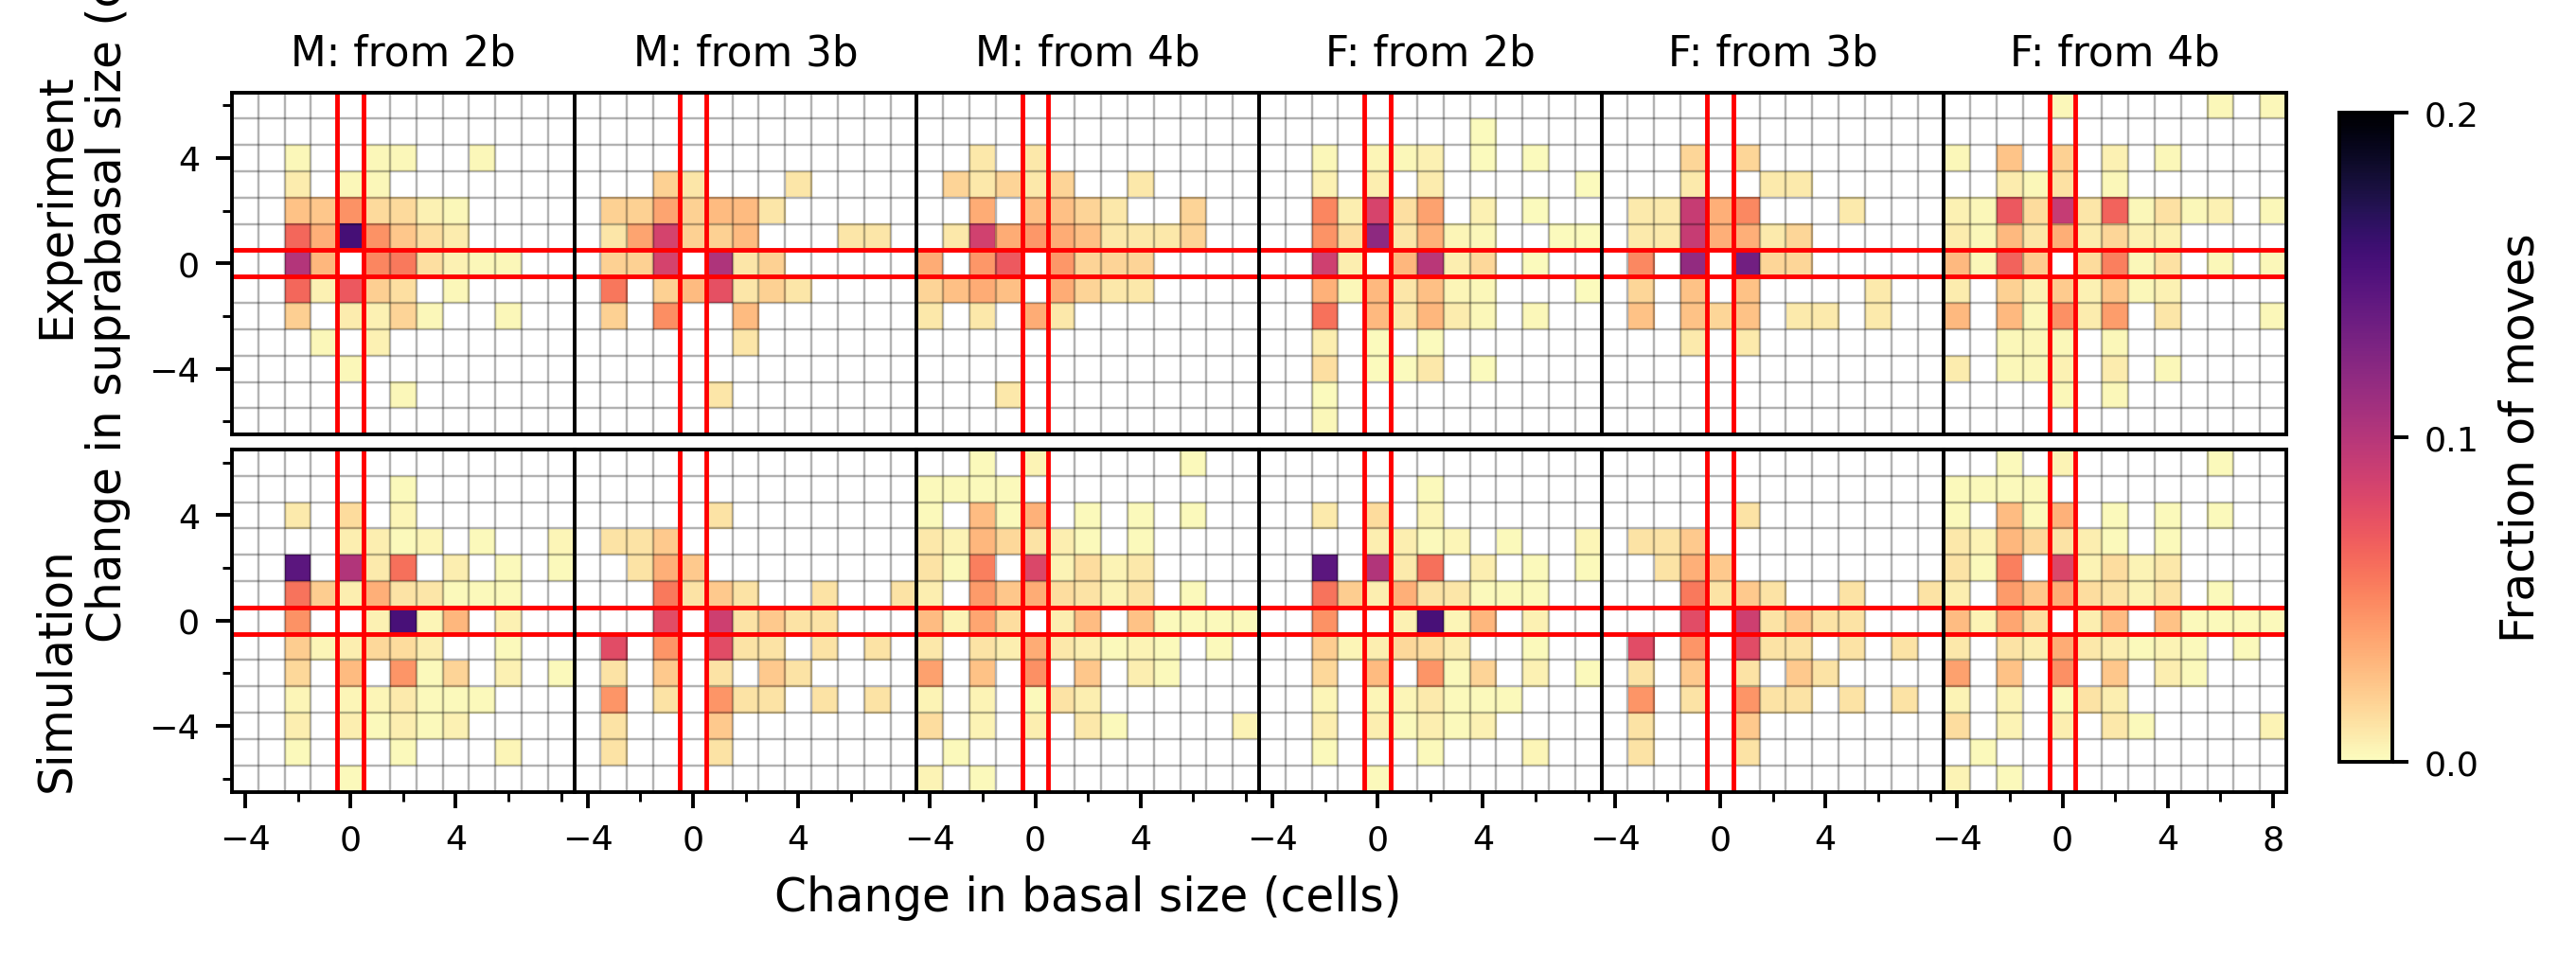

In [90]:
def plot_moves(livesize, init_bas = None, init_sup = None, use_log = False, max_move = 15, normalise = False, 
               tstart = 0, plot = True, tit_prefix = '', vmax = None, cbar = True, labels = True):
    
    if init_bas is None and init_sup is None:
        tit = 'All moves'
    elif init_bas is not None and init_sup is None:
        tit = 'from ' + str(init_bas) + 'b'
    elif init_bas is None and init_sup is not None:
        tit = 'from ' + str(init_sup) + 's'
    elif init_bas is not None and init_sup is not None:
        tit = 'from (' + str(init_bas) + 'b,' + str(init_sup) + 's)'
    
    tit = tit_prefix + tit
    
    moves = livesize[:,tstart+1:,0:2] - livesize[:,tstart:-1,0:2] #lag-1 moves, can also do higher order
    ntimes = moves.shape[1]
    moves[np.abs(moves) > 90] = -max_move

    allmoves = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    for t in range(moves.shape[1]):
        for m in range(moves.shape[0]):
            if init_bas is not None and livesize[m,t+tstart,0] != init_bas:
                continue
                
            if init_sup is not None and livesize[m,t+tstart,1] != init_sup:
                continue
                
            allmoves[t,moves[m,t,0], moves[m,t,1]] += 1
        
    allmoves[:,0,0] = 0
    allmoves[:,-max_move,-max_move] = 0

    np.sum(allmoves,0)
    for mb in range(-9,11):
        for ms in range(-9,11):
            if np.sum(allmoves,0)[mb,ms] > 0:
                #print(mb,ms, allmoves[:,mb,ms])
                continue


    allmoves2 = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    allmoves2[:,:max_move,:max_move] = allmoves[:,-max_move:,-max_move:]
    allmoves2[:,:max_move,-max_move:] = allmoves[:,-max_move:,:max_move]
    allmoves2[:,-max_move:,:max_move] = allmoves[:,:max_move,-max_move:]
    allmoves2[:,-max_move:,-max_move:] = allmoves[:,:max_move,:max_move]
    
    allmoves2[: -max_move,-max_move] = 0

    if normalise:
        allmoves2 = allmoves2/np.sum(allmoves2)
            
    if plot:
        if use_log:
            toplot = np.log2(np.sum(allmoves2,0).T)
        else:
            toplot = np.sum(allmoves2,0).T.astype('float')
            toplot[toplot == 0.0] = np.nan
        
        plt.imshow(toplot, extent=[-max_move - 0.5,max_move - 0.5,-max_move - 0.5,max_move - 0.5], 
                   origin='lower', cmap = 'magma_r', vmin = 0.0, vmax = vmax) #PuRd#magma_r
        if labels:
            plt.xlabel('Change in basal size (cells)')
            plt.ylabel('Change in suprabasal size (cells)')
        if cbar:
            if use_log:
                plt.colorbar(label = 'log2(# moves)')
            else:
                plt.colorbar(label = 'Fraction of moves')#, ticks = [0, 0.05, 0.1, 0.15])
        plt.vlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.hlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.vlines(np.arange(-0.5,1.,1),-max_move,max_move, color = 'r', linestyles='-', alpha = 1.0, linewidth = 1)
        plt.hlines(np.arange(-0.5,1,1), -max_move,max_move, color = 'r', linestyles='-', alpha = 1.0, linewidth = 1)
        plt.ylim([-max_move,max_move])
        plt.xlim([-max_move,max_move])
        plt.xticks(np.arange(-max_move,max_move+1,4))
        plt.yticks(np.arange(-max_move,max_move+1,4))
        plt.xticks(np.arange(-max_move,max_move+1,2), minor = True)
        plt.yticks(np.arange(-max_move,max_move+1,2), minor = True)        
        plt.title(tit)
        
        if not labels:
            plt.xticks([])
            plt.yticks([])
    
    return allmoves


def make_axis(max_move, i, xlabel_loc = 2, ncols = 3, j = 0, nrows = 1):
    xticks = np.arange(-max_move,max_move+1,2)
    if (i-1) % ncols > 0:
        plt.yticks([])
        plt.yticks([], minor = True)
        plt.ylabel('')
    else:
        plt.yticks(xticks[::2])
        plt.yticks(xticks, minor = True)
    
    if nrows > 1:
        if j > 0:
            plt.ylabel('')

    if j == (nrows - 1):
        if (i - 1) % ncols != xlabel_loc:
            plt.xlabel('')

        xticks = np.arange(-max_move,max_move+1,2)
        plt.xticks(xticks, minor = True) 
        if (i - 1) % ncols < (ncols - 1):
            xticks = xticks[xticks < 8]
        plt.xticks(xticks[::2])  
    else:
        plt.xticks([])
        plt.xlabel('')



sex = 'M'


plt.figure(figsize = (8,2.8), dpi = 350)
max_move = 20
i = 1

j = 0
for sex in ['M', 'F']:
    exp_data = exp_datasets[sex]
    sim_data = sim_datasets[sex]
    i = 1
    for b in [2,3,4]:
        plt.subplot(2,6,i+3*j)
        ax = plt.gca()
        plot_moves(exp_data.raw_data['clone_anal'].live_bas_sb, init_bas = b, init_sup = None, use_log = False, 
                    max_move = max_move, normalise = True, tstart = 0, plot = True, tit_prefix = f'{sex}: ', vmax = 0.2,
                    cbar = False, labels = True)
        
        make_axis(max_move, i+3*j, 2, 6, 0, 2)
        plt.xlim([-4 - 0.5,8.5])
        plt.ylim([-6.5,6.5])
        plt.xticks([])
        plt.xticks([], minor = True)
        plt.xlabel('')
        i += 1  

    i = 1
    for b in [2,3,4]:
        plt.subplot(2,6,6+i+3*j)
        ax = plt.gca()
        plot_moves(sdt.raw_data['clone_anal'].live_bas_sb, init_bas = b, init_sup = None, use_log = False, 
                    max_move = max_move, normalise = True, tstart = 0, plot = True, tit_prefix = f'{sex} ', vmax = 0.2,
                    cbar = False, labels = True)
        
        make_axis(max_move, 6+i+3*j, 2, 6, 1, 2)
        plt.xlim([-4 - 0.5,8.5])
        plt.ylim([-6.5,6.5])
        plt.title('')
        plt.ylabel('')
        i += 1
    j += 1
    
#plt.tight_layout()
plt.subplots_adjust(wspace=0.0, hspace=0)
fig = plt.gcf()
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])  # [left, bottom, width, height]
mappable = plt.cm.ScalarMappable(cmap='magma_r', norm=plt.Normalize(vmin=0, vmax=0.2))
cbar = fig.colorbar(mappable, cax=cbar_ax, ticks = [0,0.1,0.2])
cbar.set_label('Fraction of moves')

fig.text(0.05, 0.75, 'Experiment', va='center', rotation='vertical', fontsize=10)
fig.text(0.05, 0.25, 'Simulation', va='center', rotation='vertical', fontsize=10)
plt.savefig(f'Figures/Fig3_two_progenitor/F3_transitions.pdf', dpi = 300)
plt.show()



In [91]:
best_fits = {}

for corrTD in [0.0, 0.5, 1.0]:
    for corrST in [-1.0, 1.0]:
        mets1 = {}
        for sex in ['castre', 'M', 'F']:
            if sex == 'M':
                exp_file = '../../experiment/2410_Dan/dan_2410_ctr_M.pkl'
                rhoS = 0.3
                cv_sb = 1.0
                q = 0.55
                r = 0.15
            elif sex == 'F':
                exp_file = '../../experiment/2410_Dan/dan_2410_ctr_F.pkl'
                rhoS = 0.275
                cv_sb = 0.1   
                q = 1.0 #0.75
                r = 0.125
            else:
                exp_file = '../../experiment/2410_Dan/dan_2412_castre.pkl'
                rhoS = 0.275
                cv_sb = 1.0    
                q = 0.75
                r = 0.1

            for mode in [0]:
                if mode == 0:
                    savefolder = 'modelling/ST2D_0D_finale/'
                    nseeds = 1
                    s0 = topt.sim_anneal(sim_model.ST2D_0D, { 'r': [r],
                                                        'CVd_D': [1.0],
                                                        'corrSS': [0.0],
                                                        'corrDD': [0.0],
                                                        'q': [q]},
                                        params = {'tau': tau, 'refractT': -1, 'corrTT': -1.0,
                                                'CVd_T': -1.0, 'corrTD': cTD, 'rhoS': rhoS,
                                                'CVd_S': cvS, 'corrST':  cST}, simtype = 'h',
                                    exp_file = exp_file,  exp_prefix = 'ctr', tshift = 2.0, metrics = mets,
                                    compute_kwargs = compute_kwargs, toCalculate = toCalculate,
                                move_seed = np.abs(0),  use_linear = ['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrDD', 'corrSS'],
                                move_sizes =     {'r': 0.025, 'rhoS':  0.025, 'q': 0.025, 'CVd_S':  0.05, 'CVd_D':  0.05, 'corrST':  0.05, 'corrDD':  0.05, 'corrSS':  0.05},
                                free_param_min = {'r': 0.00, 'rhoS':   0.1, 'q':  0.0, 'CVd_S':  0.0, 'CVd_D':  0.0, 'corrST':  0.0, 'corrDD':  0.0, 'corrSS':  0.0},
                                free_param_max = {'r': 1.00, 'rhoS':   1.0, 'q':  1.01, 'CVd_S': 1.04, 'CVd_D': 1.04, 'corrST': 1.04, 'corrDD': 1.04, 'corrSS': 1.04})
                    
            s0.load_existing(tsteps = -30, ncells = ncells, savefolder = savefolder, 
                            tscalevals = -np.arange(2,14,0.05), 
                            shedvals = -np.arange(0.2, 2.0, 0.1), 
                            postopt_params = {'sbas_cv': np.arange(0.1, 1.01, 0.1)})
            s0.searchspace = s0.searchspace[(s0.searchspace['corrTD'] == corrTD)]
            s0.searchspace = s0.searchspace[(s0.searchspace['corrST'] == corrST)]

            if len(s0.searchspace) == 0:
                continue
            
            for met in ['ll_SPD']: 
                best_fits[(sex, met)] = s0.best_fit(met)
                if best_fits[(sex, met)] is not None:
                    mets1[(sex, met)] = best_fits[(sex, met)][met]

        if len(s0.searchspace) == 0:
            continue

        params = pd.DataFrame(best_fits).T[['r', 'rhoS', 'q', 'CVd_S', 'CVd_D', 'corrST', 'corrTD', 'corrDD', 'corrSS', 'tscale', 'tau', 'shed']]
        params['mu'] = ((params['q']-2)*params['rhoS']*params['tau'] + params['tau']*(1-params['rhoS']))/(params['rhoS']*(3-params['q']))#/params['tau']*params['tscale']
        params['rhoT1'] = params['tau']/(params['tau'] + ((3 - params['q'])*params['mu'] + (2 - params['q'])*params['tau']))
        params['rhoT2'] = params['tau']*(1-params['q'])/(params['tau'] + ((3 - params['q'])*params['mu'] + (2 - params['q'])*params['tau']))
        params['rhoD'] = params['mu']*(3-params['q'])/(params['tau'] + ((3 - params['q'])*params['mu'] + (2 - params['q'])*params['tau']))
        params['mu1'] = params['mu']
        params['mu'] = ((params['q']-2)*params['rhoS']*params['tau'] + params['tau']*(1-params['rhoS']))/(params['rhoS']*(3-params['q']))/params['tau']*params['tscale']
        params['shed']
        print('corrST', corrST, 'corrTD', corrTD, 'Mets', mets1)
        print(params.to_markdown())

corrST -1.0 corrTD 0.0 Mets {('castre', 'll_STD'): np.float64(3161.4413581616072), ('M', 'll_STD'): np.float64(5159.4459892530385), ('F', 'll_STD'): np.float64(11415.650716552916)}
|                      |     r |   rhoS |    q |   CVd_S |   CVd_D |   corrST |   corrTD |   corrDD |   corrSS |   tscale |   tau |   shed |       mu |   rhoT1 |   rhoT2 |    rhoD |     mu1 |
|:---------------------|------:|-------:|-----:|--------:|--------:|---------:|---------:|---------:|---------:|---------:|------:|-------:|---------:|--------:|--------:|--------:|--------:|
| ('castre', 'll_STD') | 0.1   |  0.275 | 0.5  |     0.5 |     0.9 |       -1 |        0 |      0.9 |      1   |    -5.65 |   100 |  -0.7  | -2.56818 |   0.275 | 0.1375  | 0.3125  | 45.4545 |
| ('M', 'll_STD')      | 0.125 |  0.3   | 0.5  |     0.5 |     0.1 |       -1 |        0 |      0.1 |      0.9 |    -6.9  |   100 |  -0.5  | -2.3     |   0.3   | 0.15    | 0.25    | 33.3333 |
| ('F', 'll_STD')      | 0.175 |  0.275 | 0.95 |   

In [74]:
best_fits

{('F', 'll_STD'): None, ('F', 'll_SPD'): None, ('F', 'ksd_b_sb'): None}

In [83]:
s0.searchspace.columns

Index(['index', 'r', 'CVd_D', 'corrSS', 'corrDD', 'q', 'tau', 'refractT',
       'corrTT', 'CVd_T', 'corrTD', 'rhoS', 'CVd_S', 'corrST', 'maxseed',
       'ksd_b_sb', 'ksd_b_sb:shed', 'ksd_b_sb:tscale', 'll_SPD', 'll_SPD:shed',
       'll_SPD:tscale', 'll_STD', 'll_STD:shed', 'll_STD:tscale', 'ksd_bas',
       'ksd_bas:shed', 'ksd_bas:tscale', 'ksd_b_sb:sbas_cv', 'll_SPD:sbas_cv',
       'll_STD:sbas_cv', 'ksd_bas:sbas_cv', 'ksd_b_sb:sweeps', 'll_SPD:sweeps',
       'll_STD:sweeps', 'ksd_bas:sweeps'],
      dtype='object')